In [18]:
%run ./functions.ipynb
random.seed(42)

In [19]:
z_by_d = {}
log_z_by_d = {}

for d in [2, 4, 6, 8, 10]:
    y_vec = np.zeros(d)
    y_vec[0] = 0.5
    log_Z, Z = compute_log_Z_even(y_vec, [0.1, 0.01])
    z_by_d[d] = Z
    log_z_by_d[d] = log_Z
    print(f"d = {d} -> log Z = {log_Z:.6f}, Z = {Z:.6f}")

d = 2 -> log Z = -1.144730, Z = 0.318310
d = 4 -> log Z = -1.596313, Z = 0.202642
d = 6 -> log Z = -1.642430, Z = 0.193509
d = 8 -> log Z = -1.400866, Z = 0.246383
d = 10 -> log Z = -0.936158, Z = 0.392131


# One simulation

## $\alpha = 0.999$

d=2


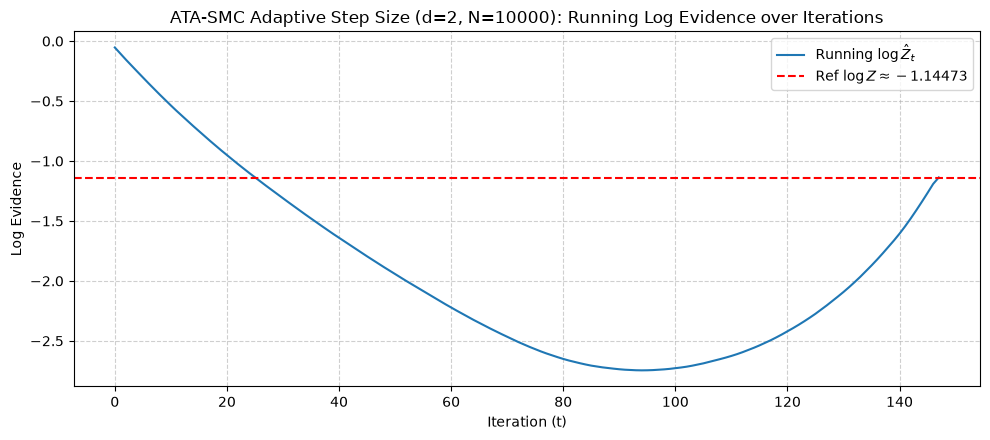

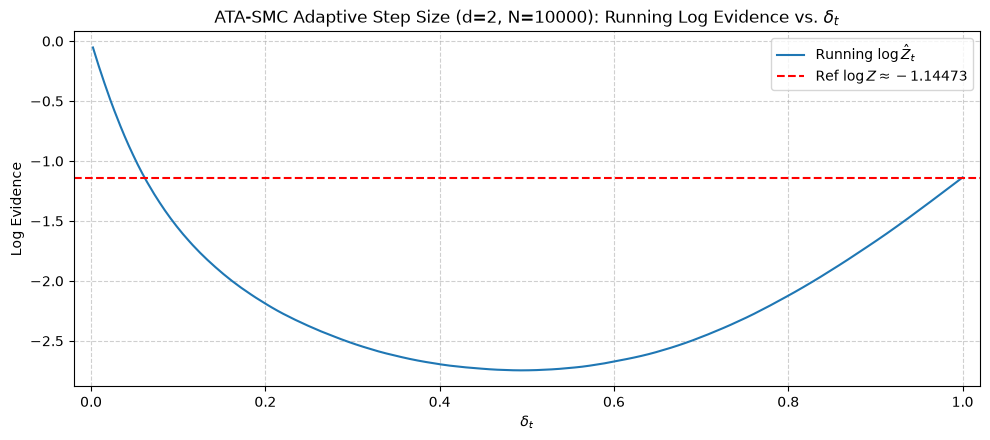

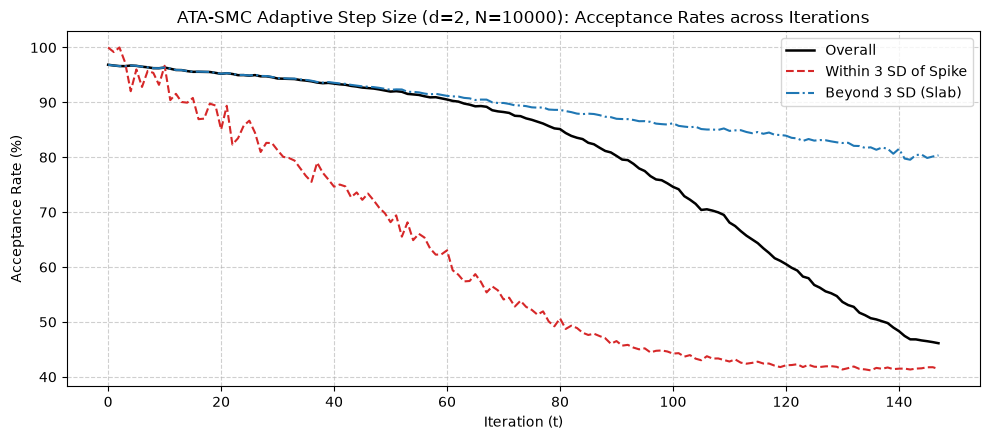

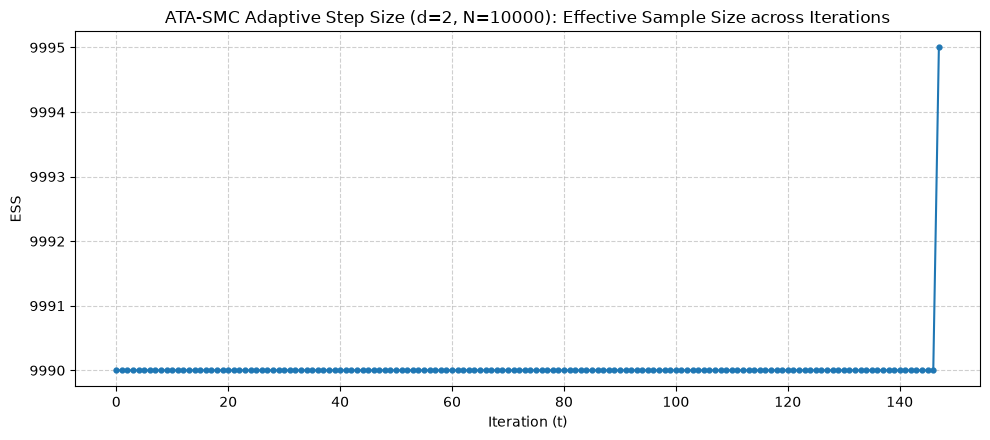

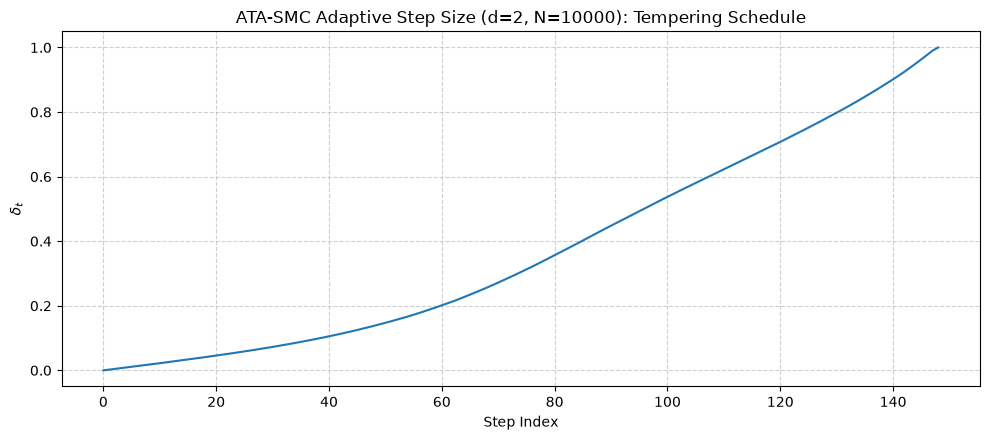

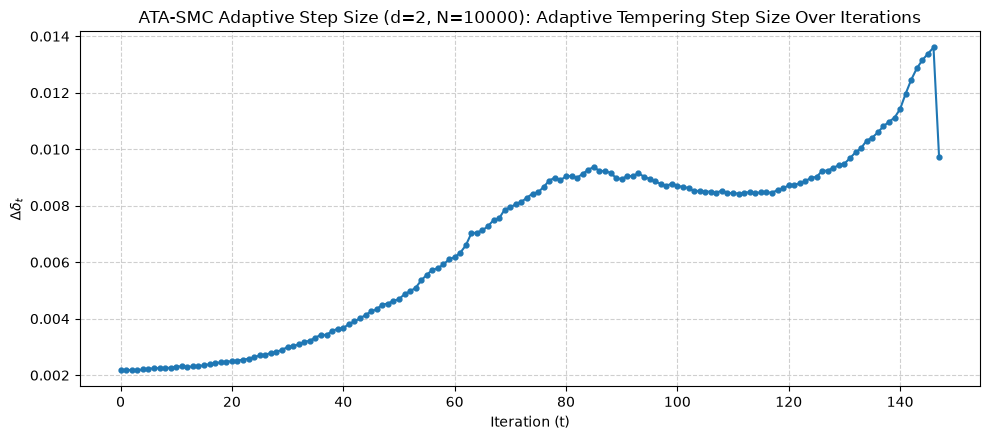

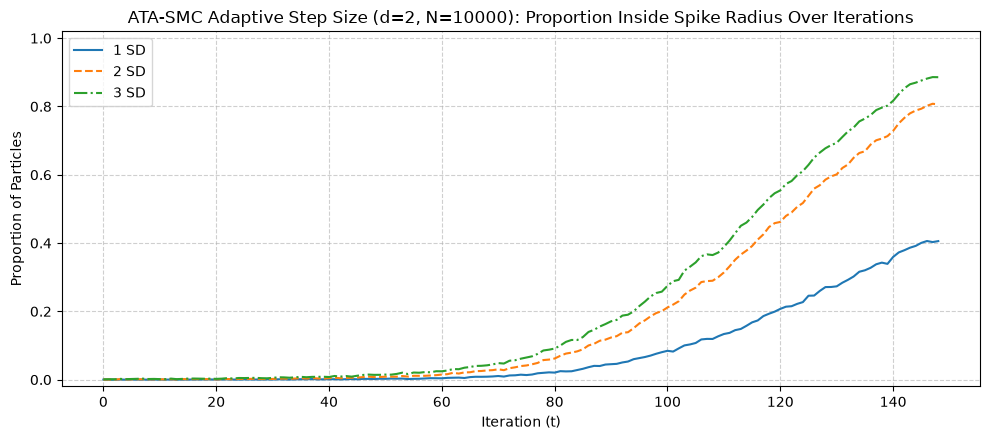

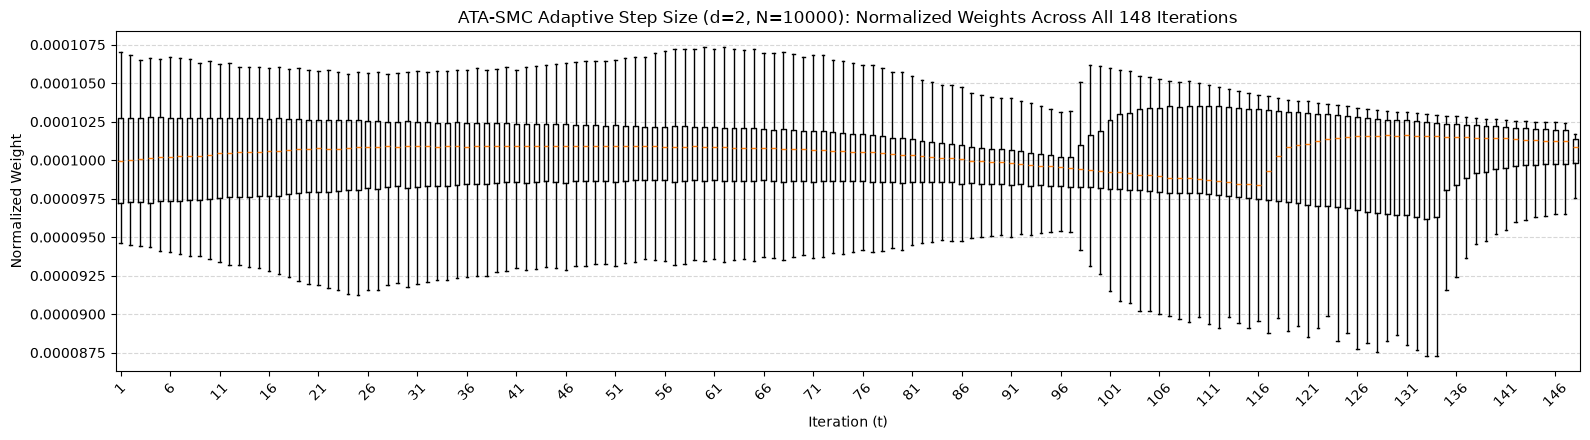

d=4


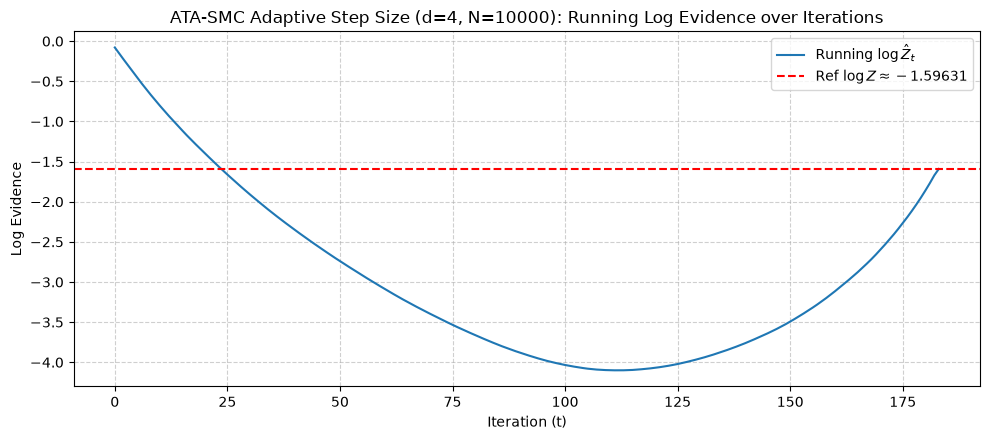

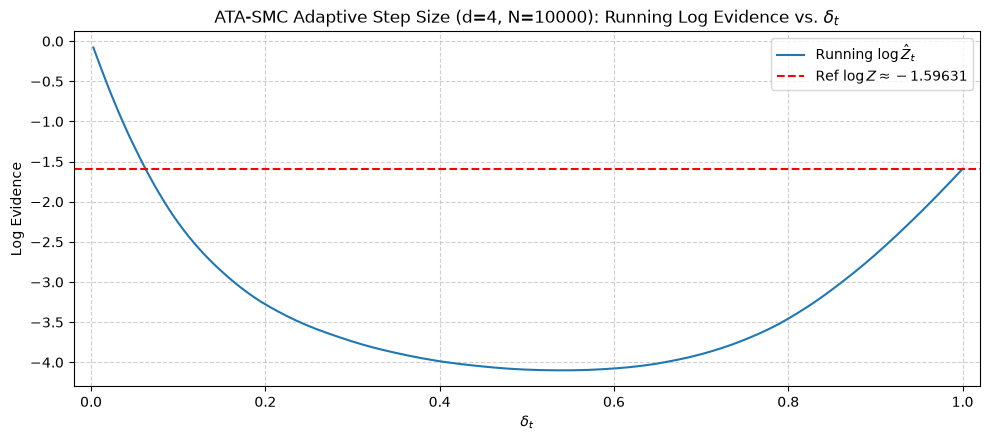

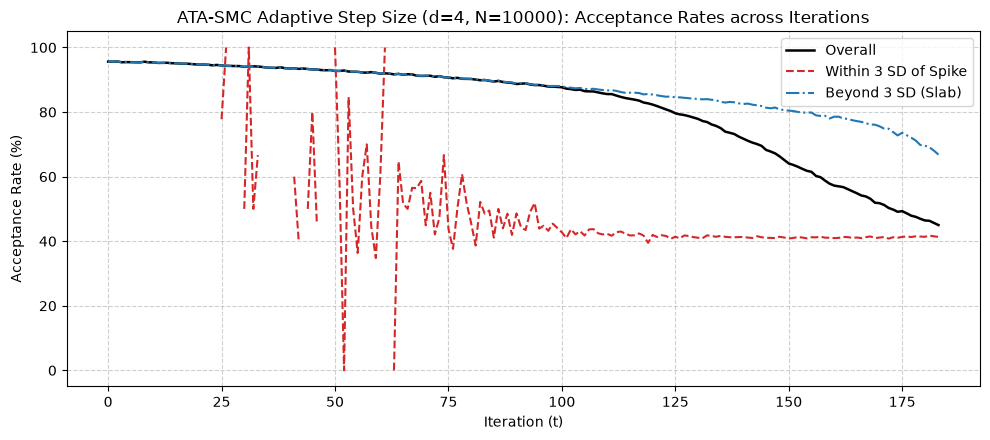

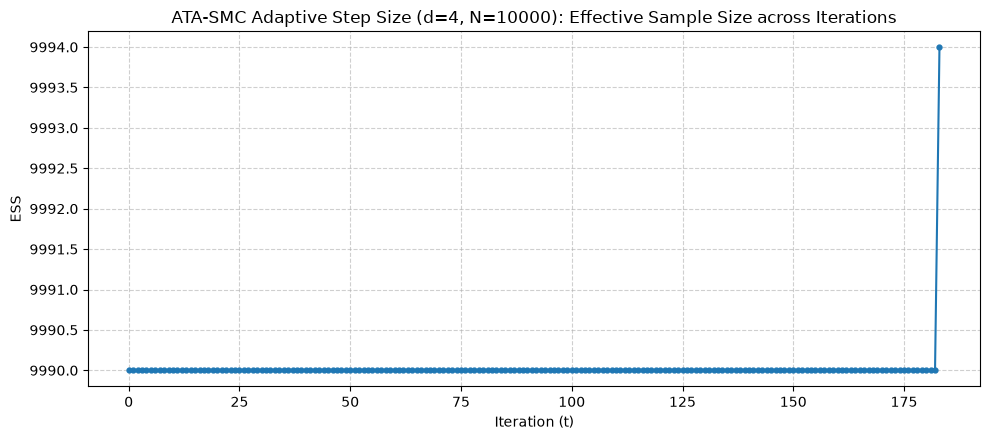

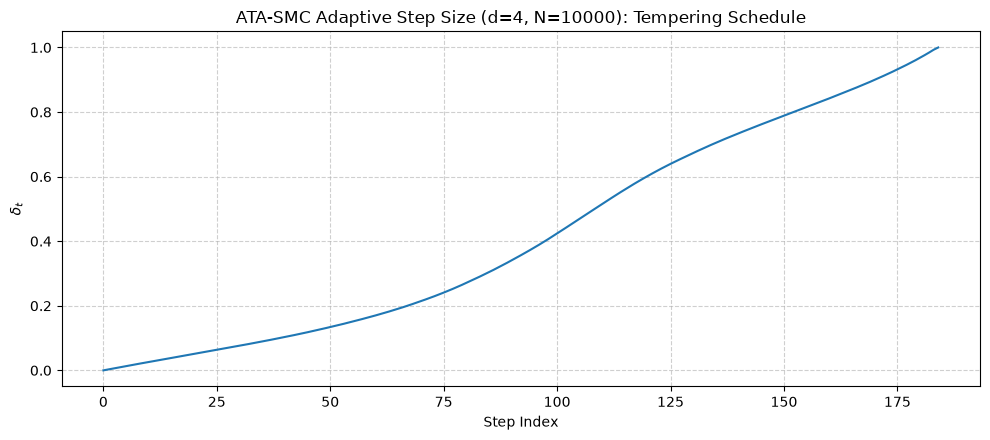

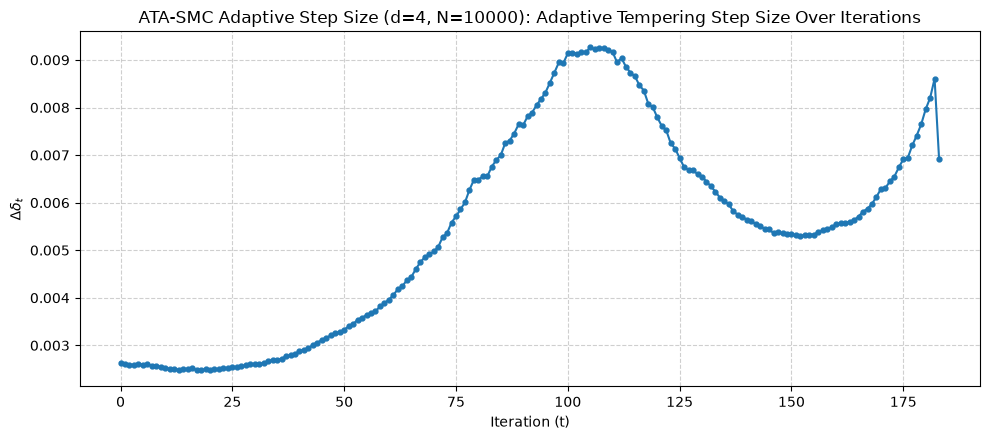

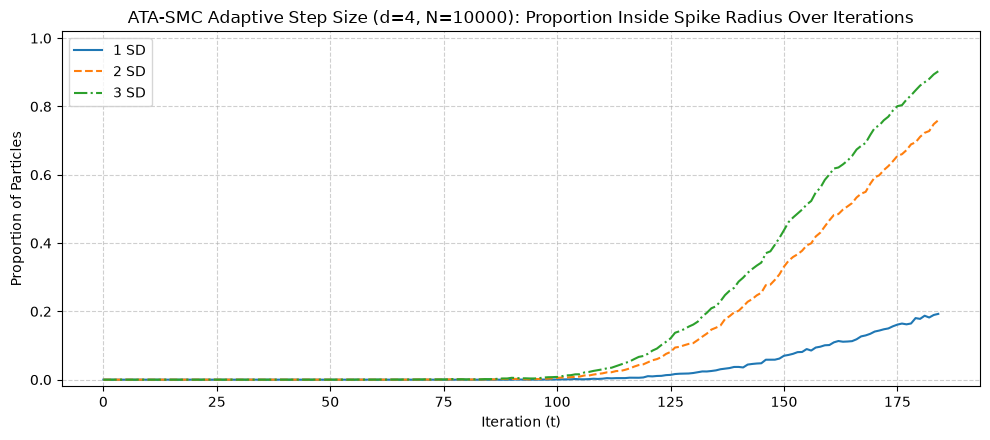

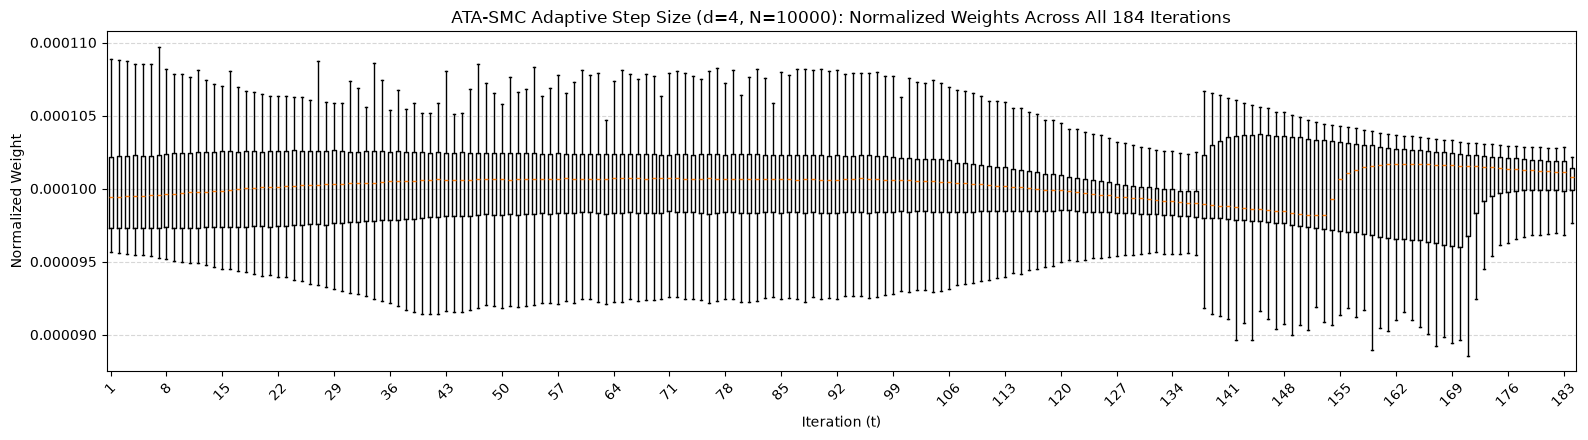

d=6


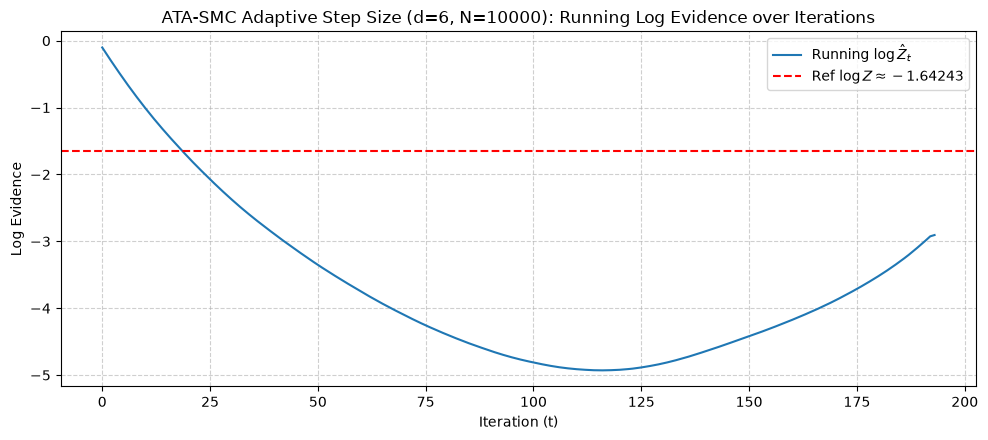

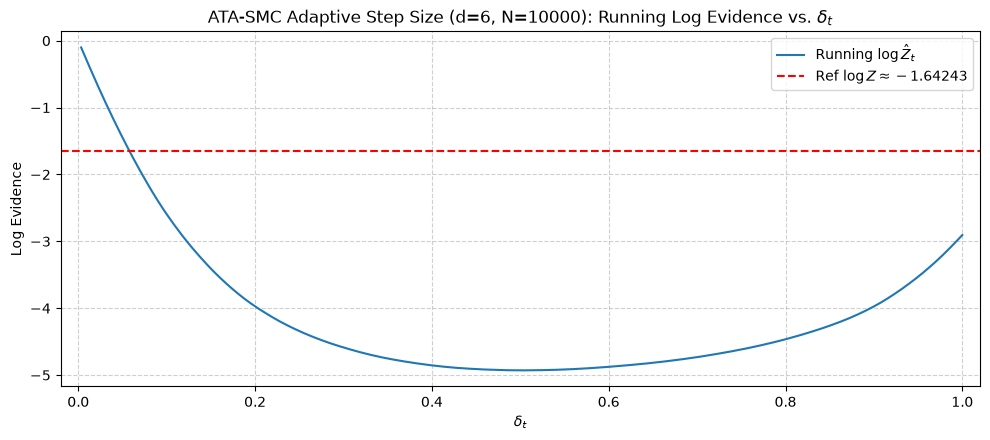

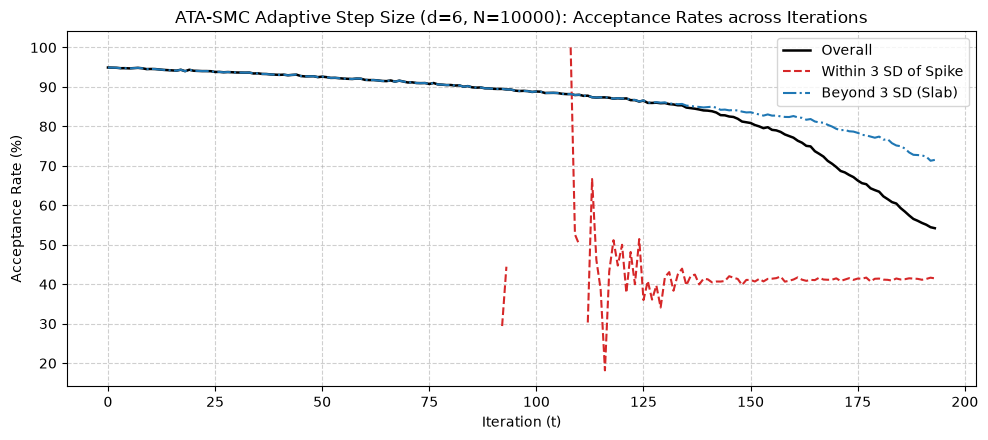

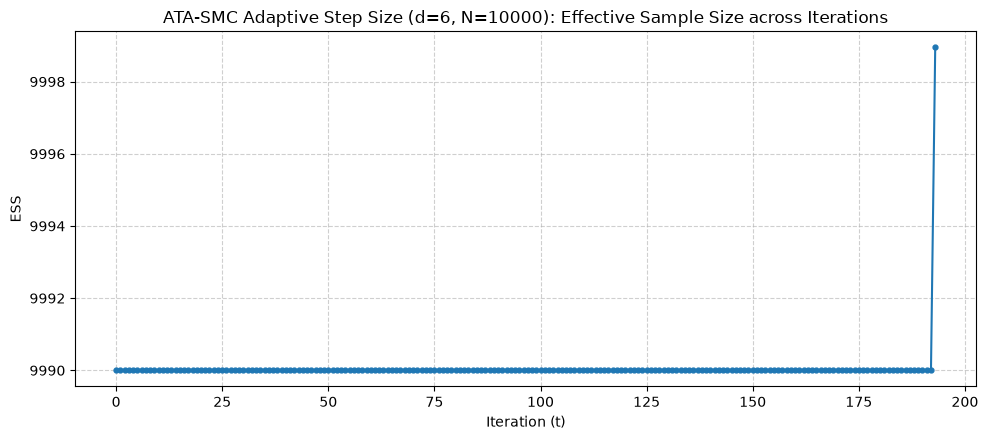

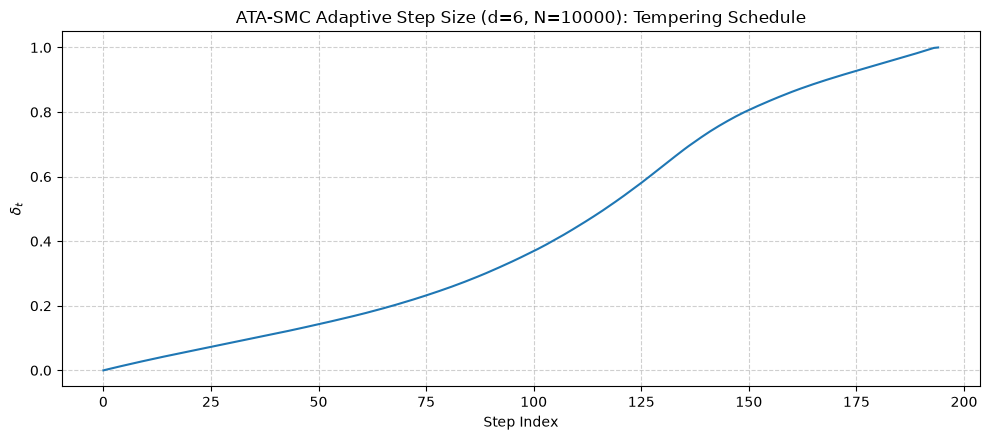

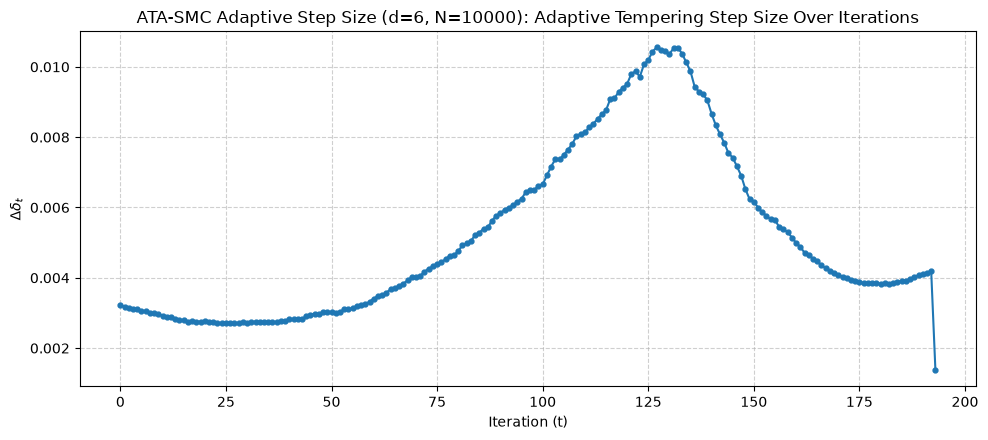

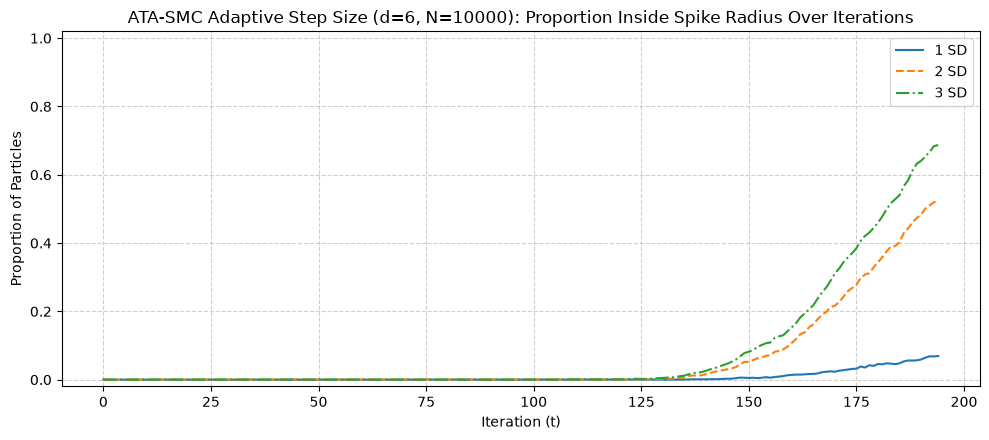

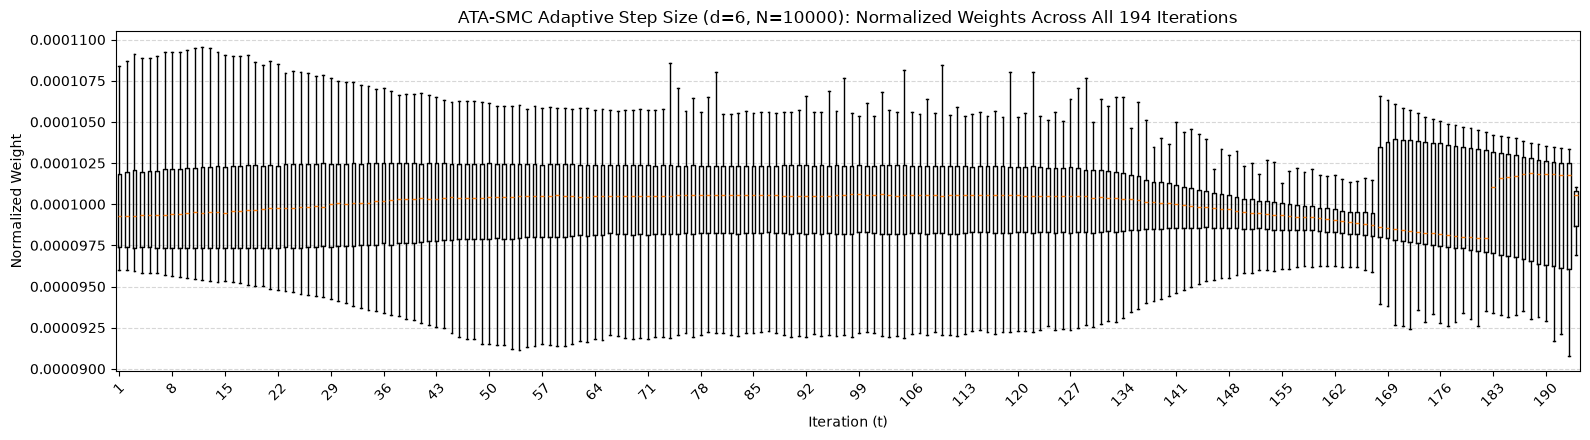

d=8


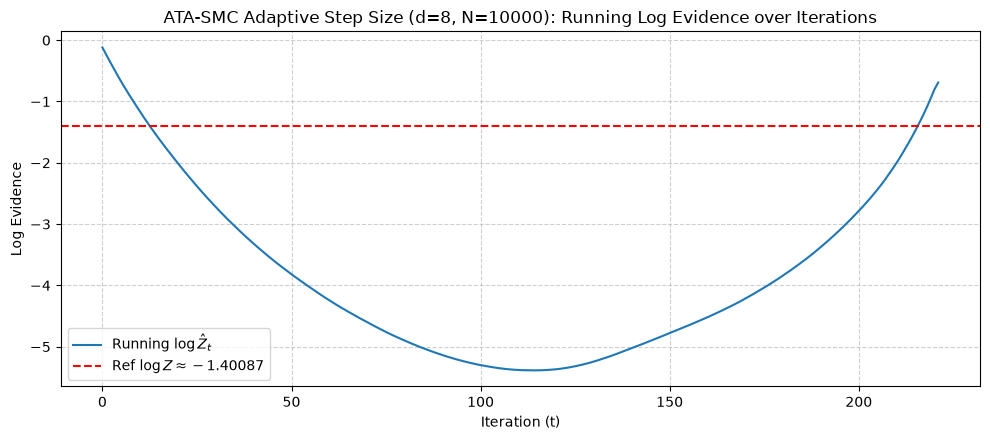

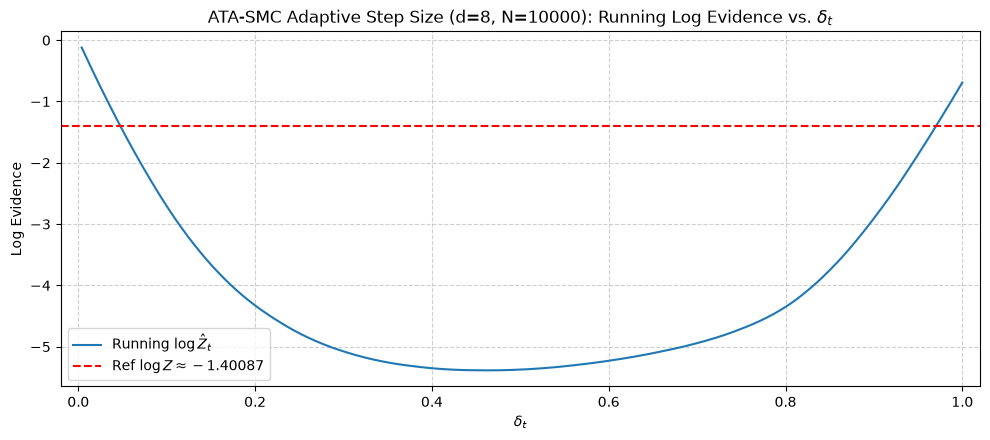

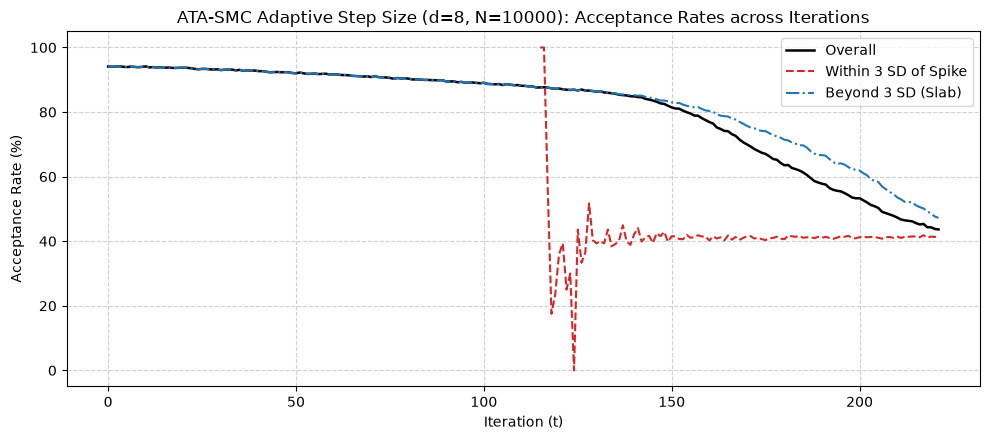

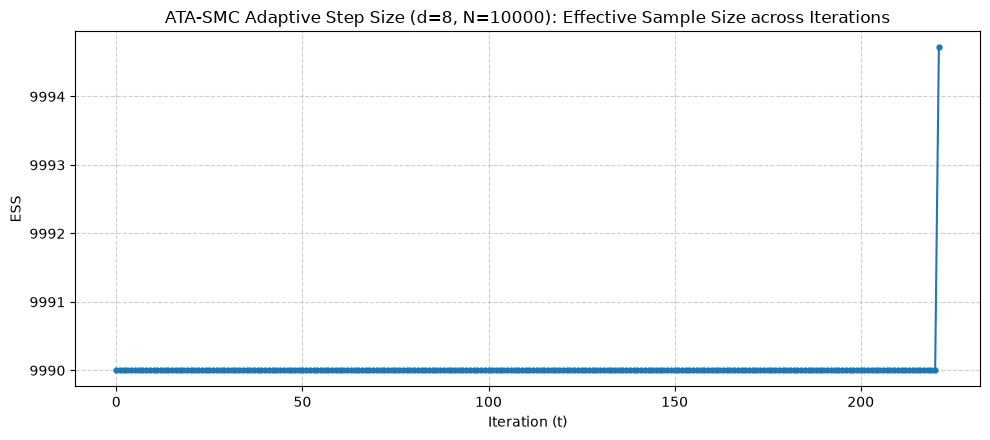

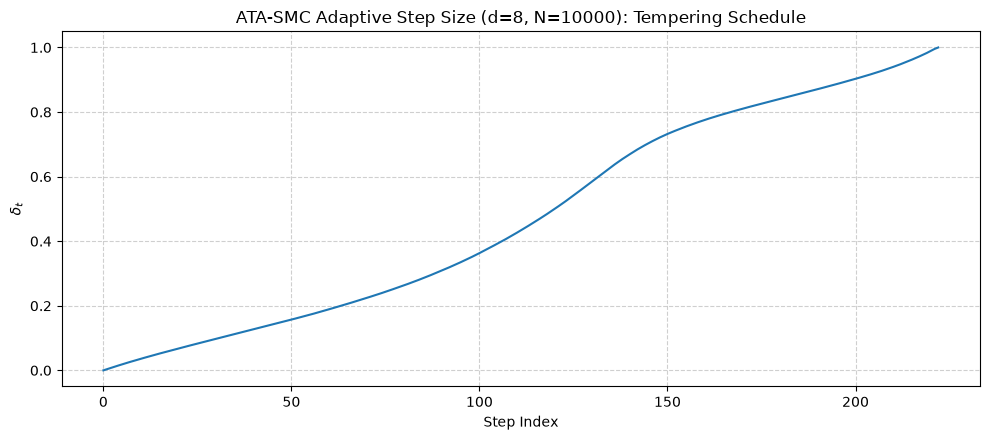

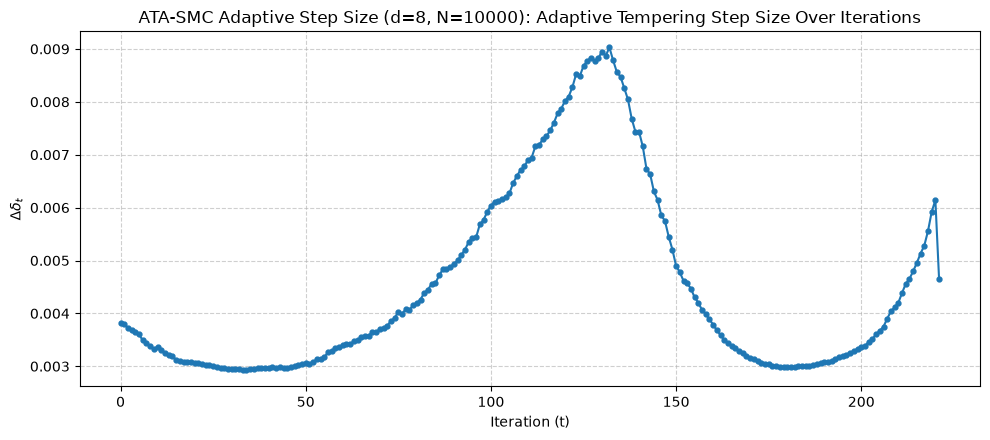

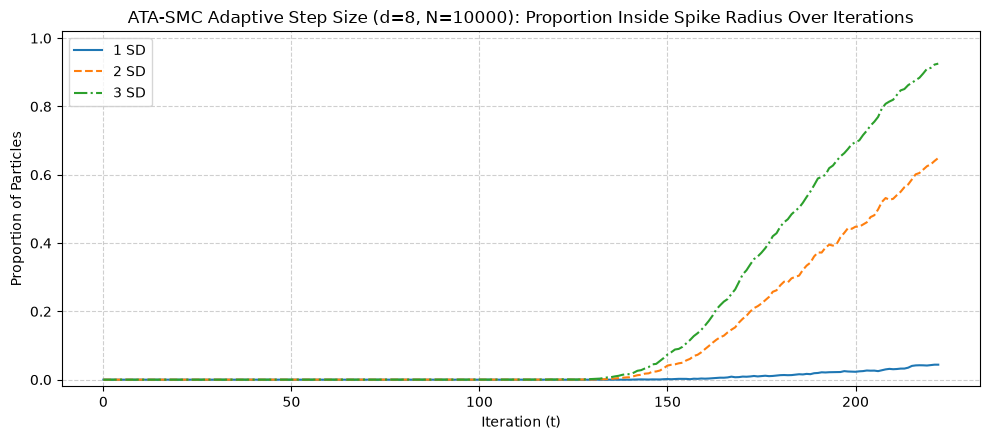

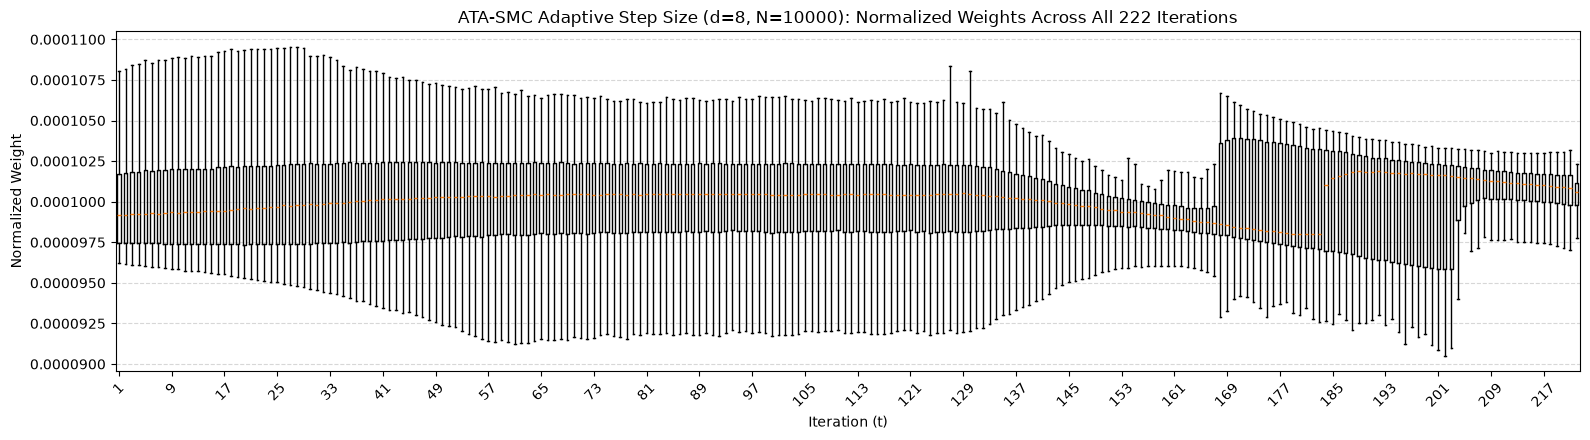

d=10


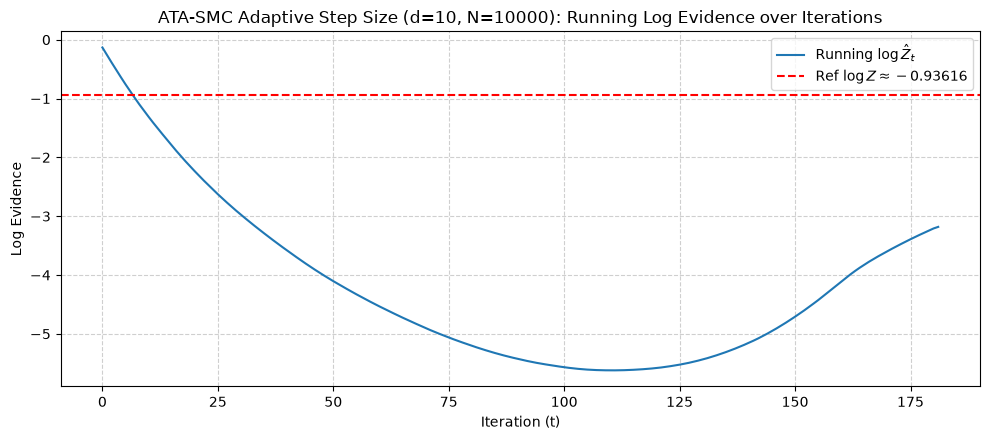

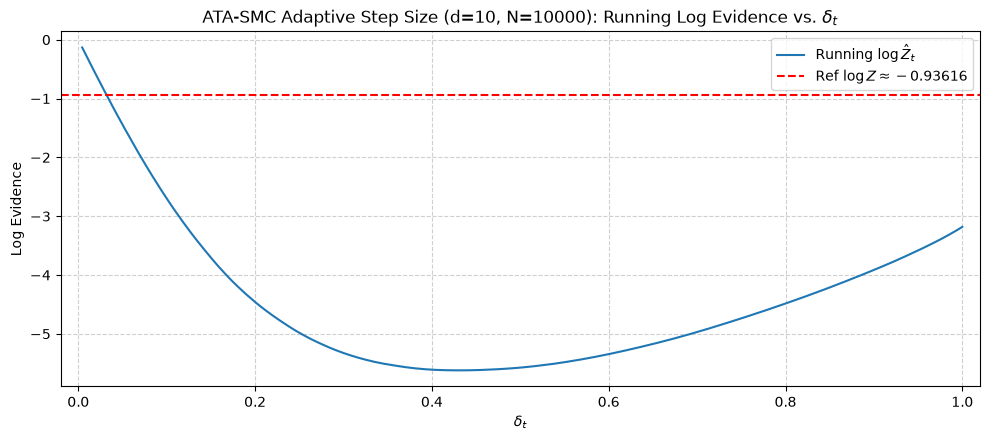

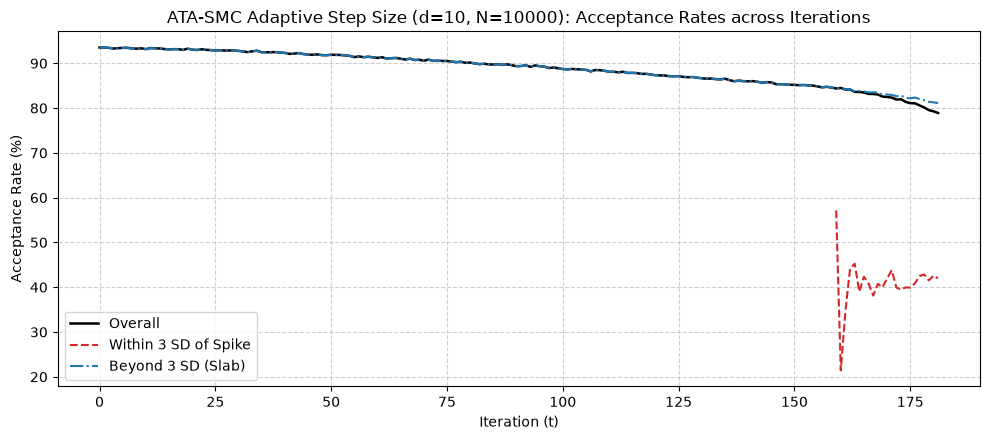

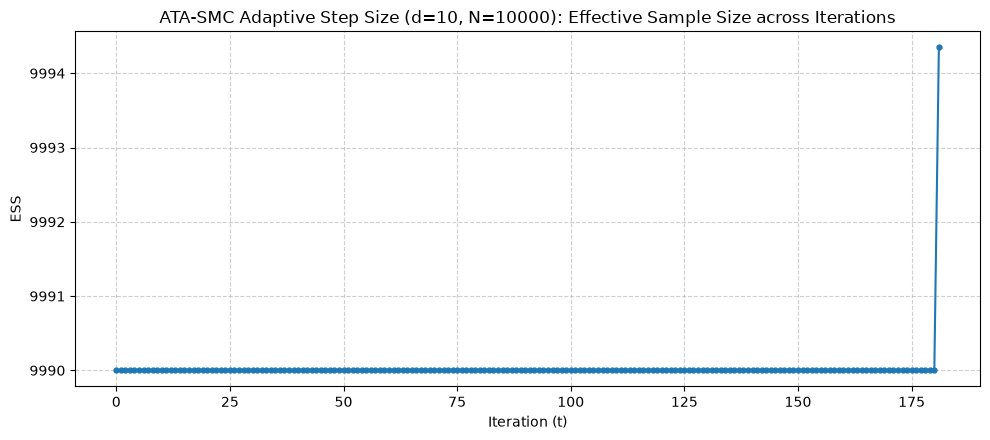

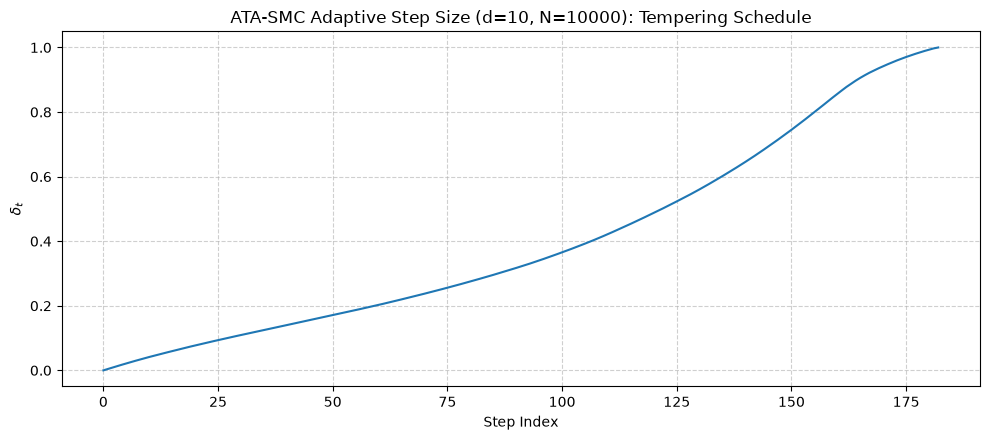

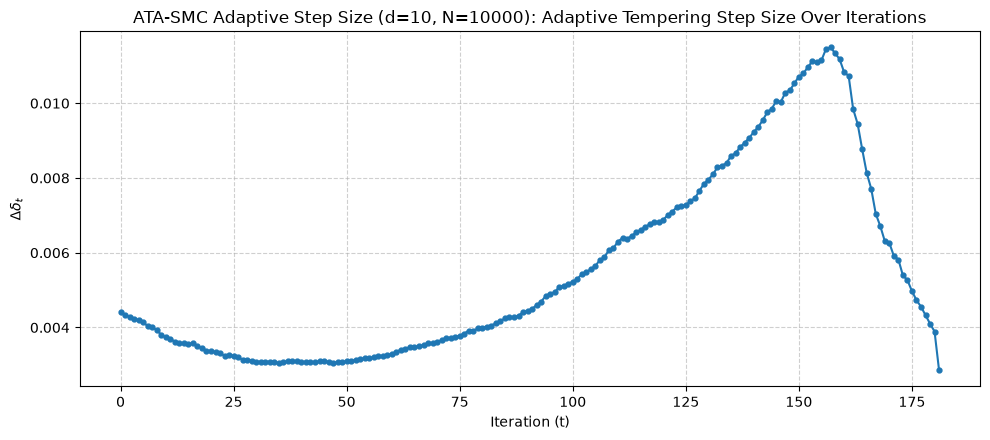

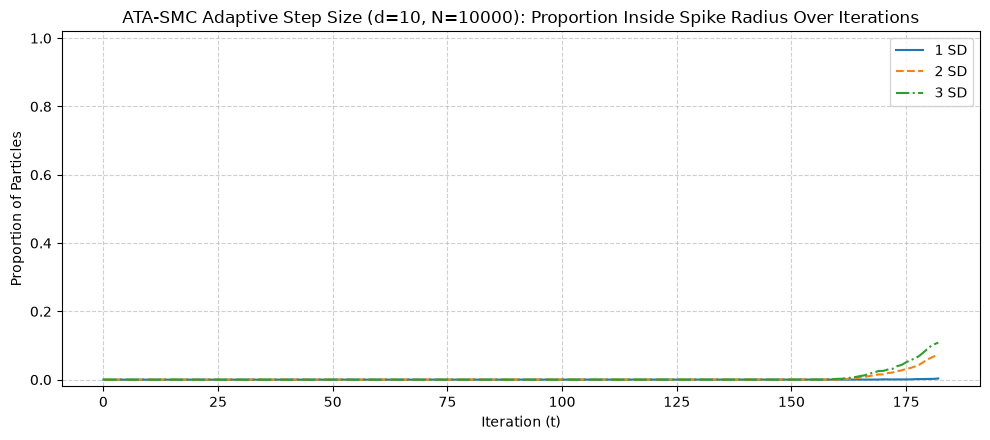

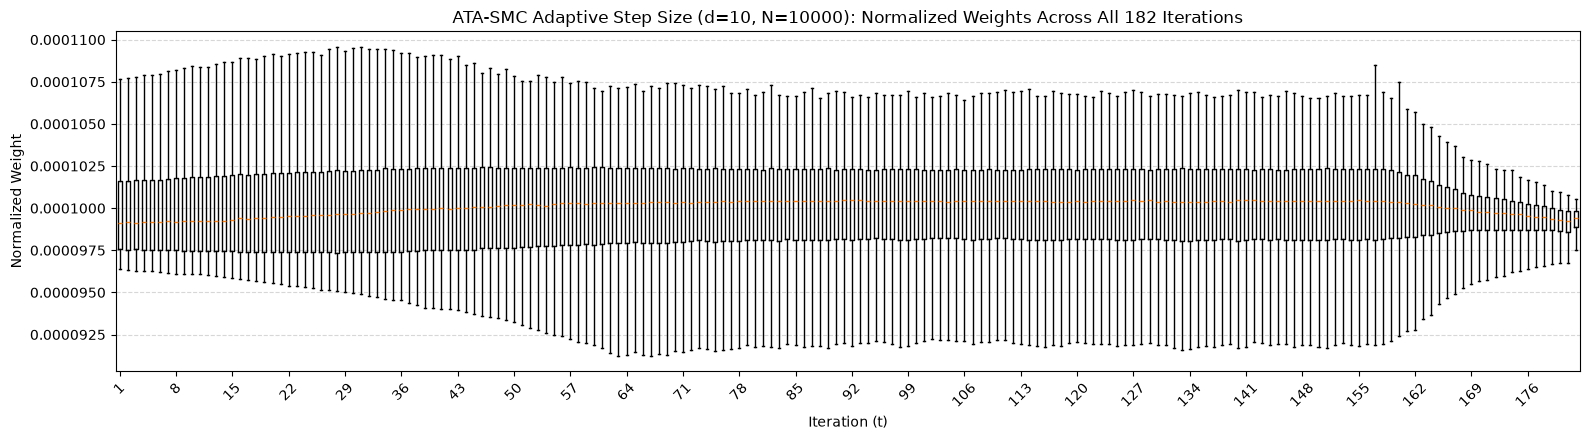

In [20]:
class Options:
    pass


dims = [2, 4, 6, 8, 10]
N = 10000
repeats = 10
num_repeats = 1


def run_ata_smc_for_d(d_val, num_repeats=1, plot_diagnostics=True):
    d_int = int(d_val)
    print(f"d={d_int}")
    ref_log_z = float(log_z_by_d[d_int])
    ref_z = float(z_by_d[d_int])

    rows = []
    for i in range(num_repeats):
        options = Options()
        options.N = N
        options.d = d_int
        options.alpha = 0.999
        options.R = repeats
        options.sig = 0.1

        np.random.seed(i)
        t_start = time.time()
        (
            log_evidence,
            count_loglike,
            gammavar,
            ess,
            log_unnormalized_w,
            normalized_w,
            prop_1sd,
            prop_2sd,
            prop_3sd,
            log_evidence_t,
            accept_rate_t,
            accept_spike_t,
            accept_slab_t,
            total_prop_spike,
            total_prop_slab,
        ) = ATA_SMC_bespoke_RW_adaptive(
            loglike_fn, logprior_fn, simprior_fn, options, False
        )
        t_elapsed = time.time() - t_start

        if plot_diagnostics:
            plot_ata_smc_diagnostics(
                gammavar=gammavar,
                log_evidence_t=log_evidence_t,
                accept_rate_t=accept_rate_t,
                accept_spike_t=accept_spike_t,
                accept_slab_t=accept_slab_t,
                prop_1sd=prop_1sd,
                prop_2sd=prop_2sd,
                prop_3sd=prop_3sd,
                normalized_w=normalized_w,
                ess=ess,
                true_log_z=ref_log_z,
                label_prefix=f"ATA-SMC Adaptive Step Size (d={d_int}, N={N})",
            )

        rows.append({
            "d": d_int,
            "repeat": i,
            "log_evidence": log_evidence,
            "ref_log_z": ref_log_z,
            "log_err": log_evidence - ref_log_z,
            "Z": np.exp(log_evidence),
            "ref_Z": ref_z,
            "count_loglike": count_loglike,
            "elapsed_sec": t_elapsed,
            "prop_1sd": prop_1sd,
            "prop_2sd": prop_2sd,
            "prop_3sd": prop_3sd,
            "total_prop_spike": total_prop_spike,
            "total_prop_slab": total_prop_slab,
        })
    return pd.DataFrame(rows)


df_ata_smc = pd.concat(
    [
        run_ata_smc_for_d(d_val, num_repeats=num_repeats, plot_diagnostics=True)
        for d_val in dims
    ],
    ignore_index=True,
)

In [21]:
df_ata_smc["ratio_spike_slab"] = df_ata_smc["total_prop_spike"] / df_ata_smc["total_prop_slab"]
df_ata_smc["true_Z"] = df_ata_smc["d"].map(z_by_d)
df_ata_smc["true_log_Z"] = df_ata_smc["d"].map(log_z_by_d)
df_ata_smc["abs_error"] = np.sqrt((df_ata_smc["Z"] - df_ata_smc["true_Z"]) ** 2)
df_ata_smc[["d", "log_evidence", "true_log_Z", "Z", "true_Z", "abs_error", "total_prop_spike", "total_prop_slab", "ratio_spike_slab"]]

,d,log_evidence,true_log_Z,Z,true_Z,abs_error,total_prop_spike,total_prop_slab,ratio_spike_slab
0,2,-1.137029,-1.144730,0.320771,0.318310,0.002461,87928,12072,7.283632
1,4,-1.591506,-1.596313,0.203619,0.202642,0.000976,85604,14396,5.946374
2,6,-2.905738,-1.642430,0.054708,0.193509,0.138801,57645,42355,1.360996
3,8,-0.690872,-1.400866,0.501139,0.246383,0.254756,61406,38594,1.591076
4,10,-3.181820,-0.936158,0.041510,0.392131,0.350621,5645,94355,0.059827


## $\alpha = 0.9999$

d=2


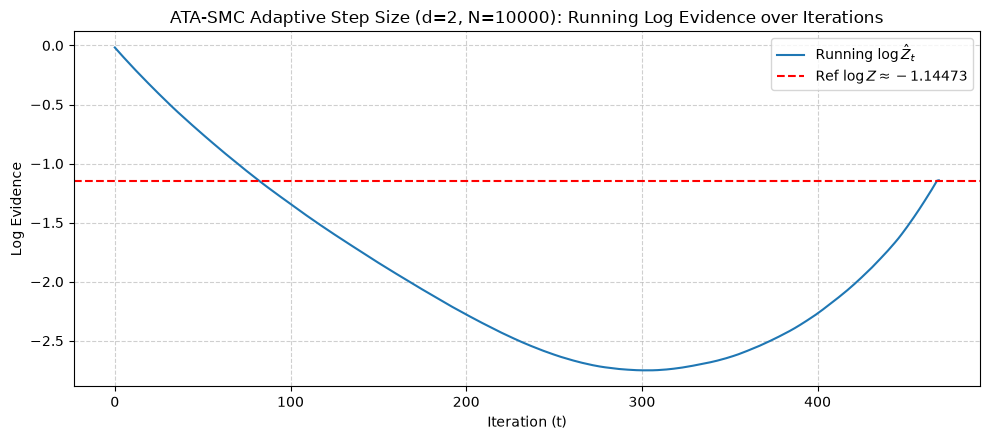

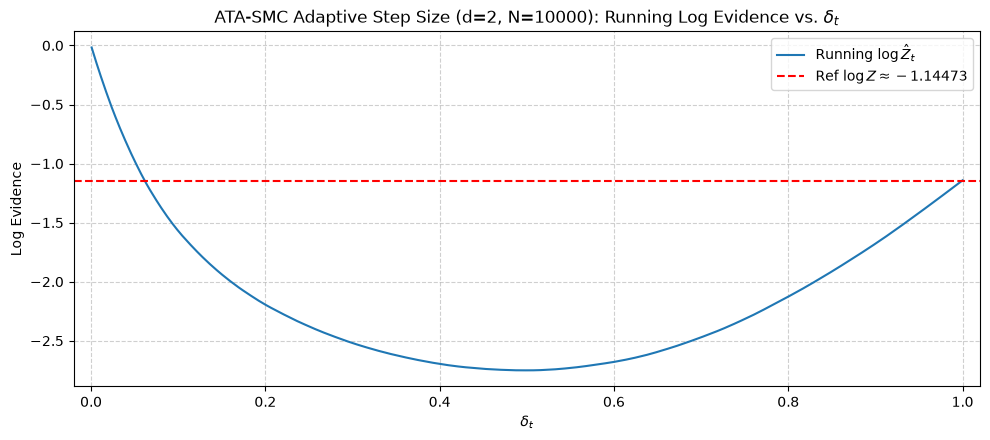

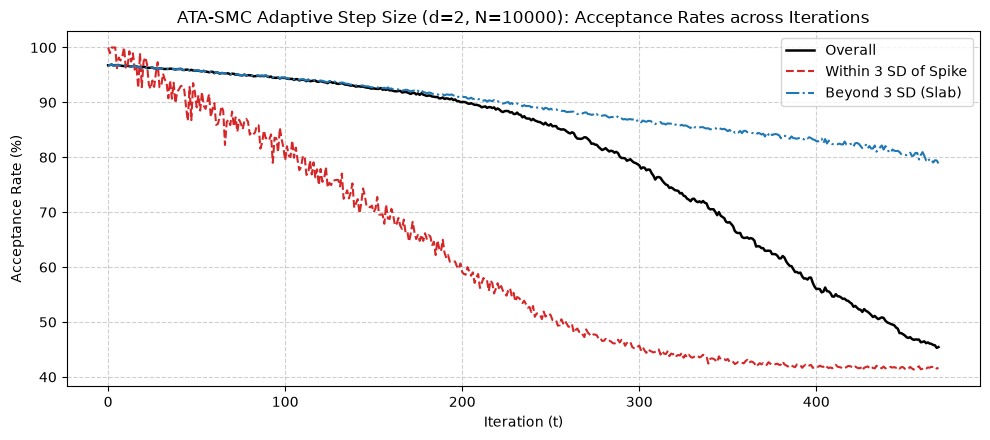

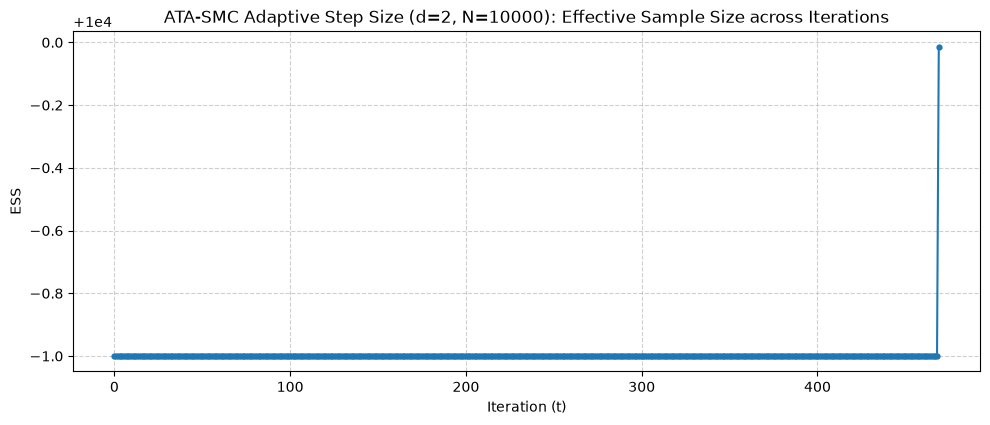

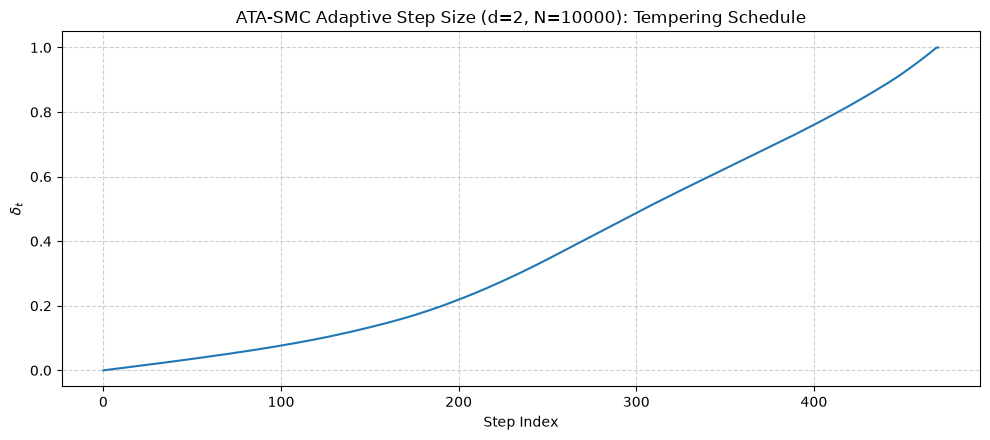

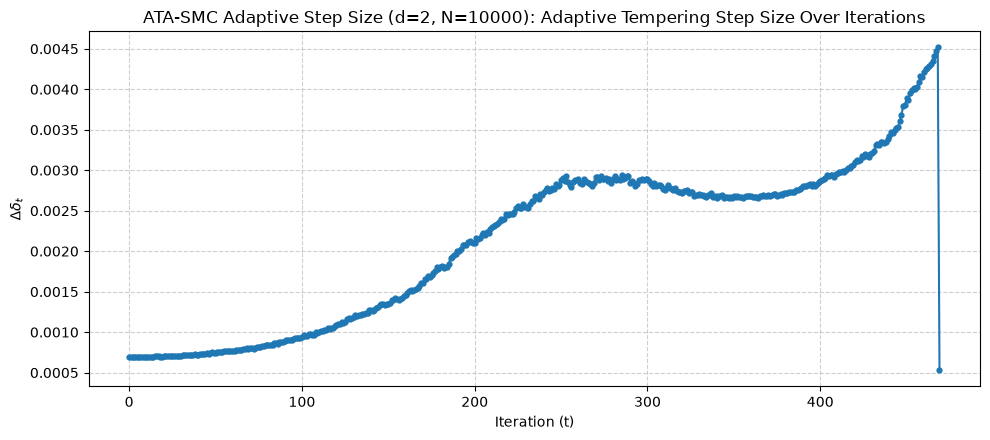

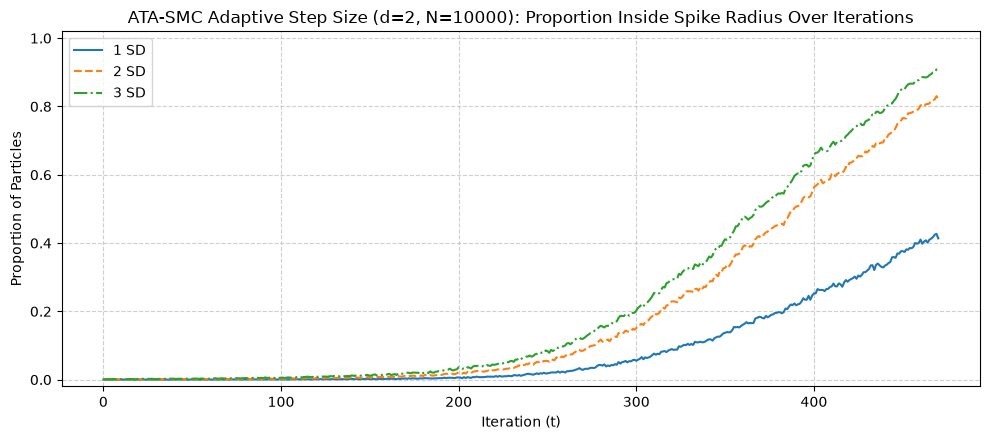

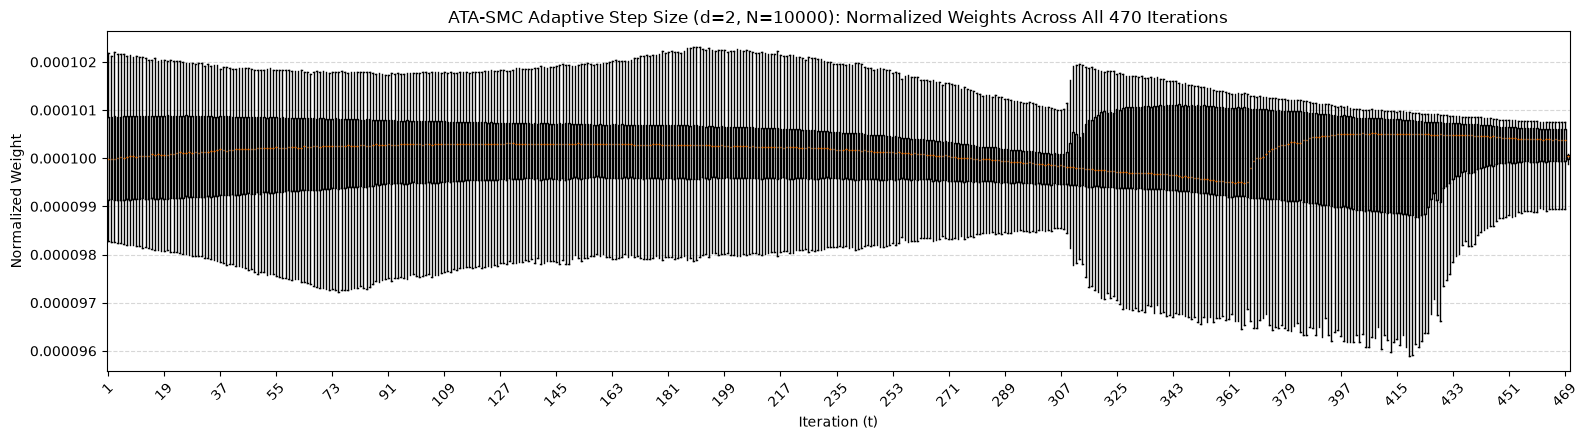

d=4


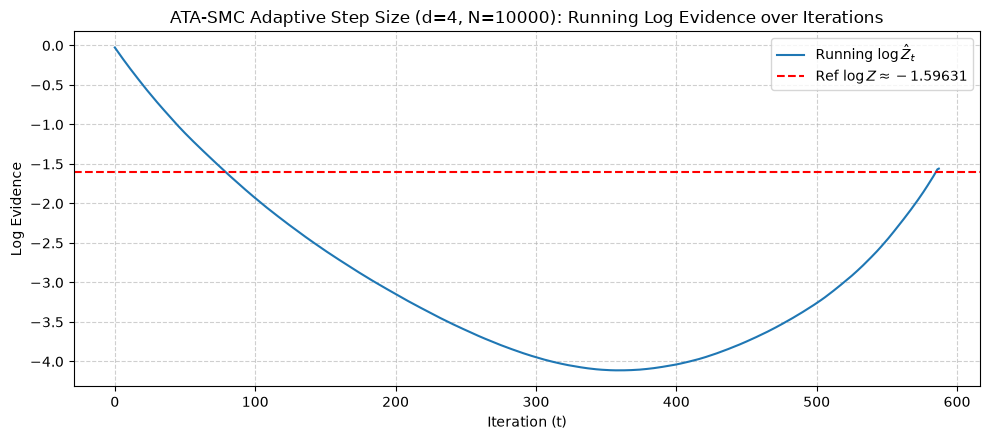

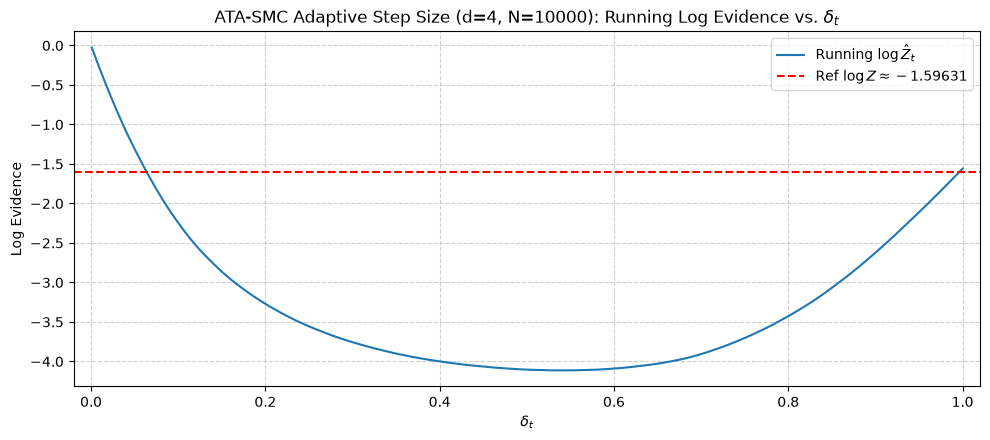

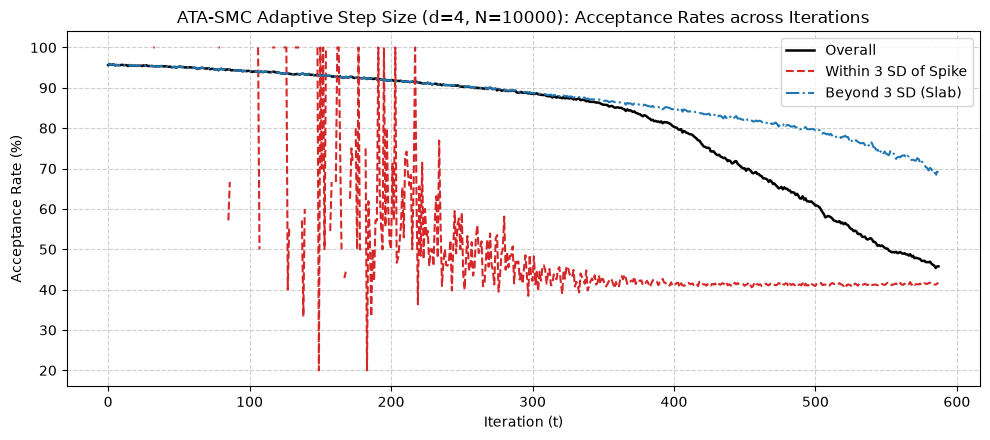

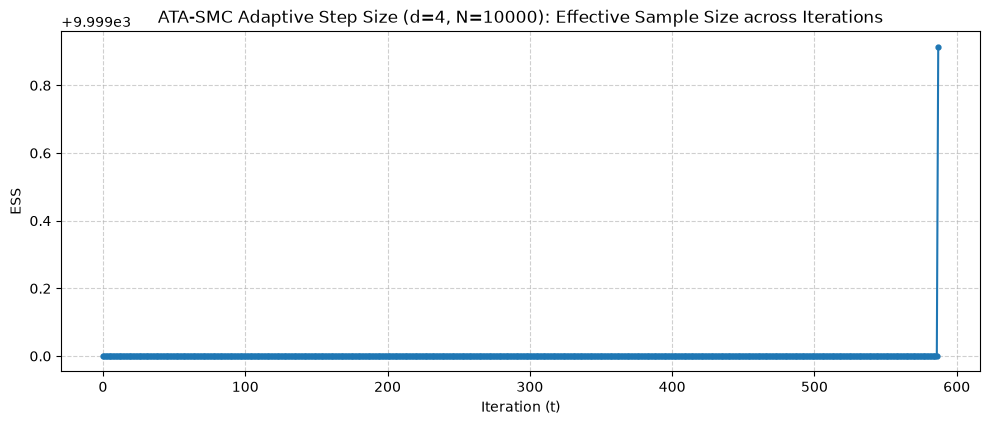

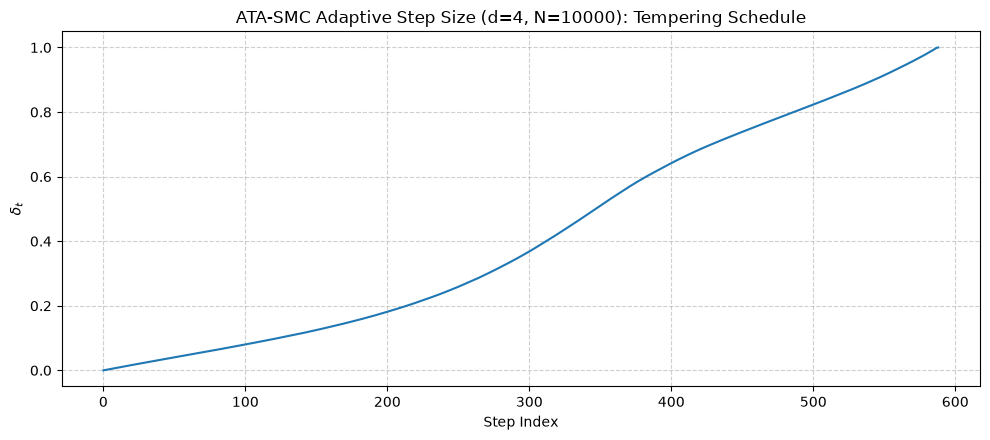

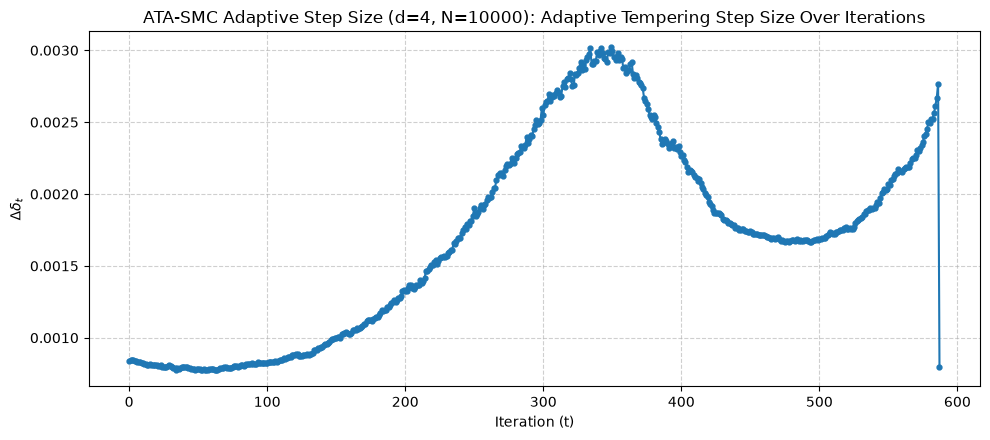

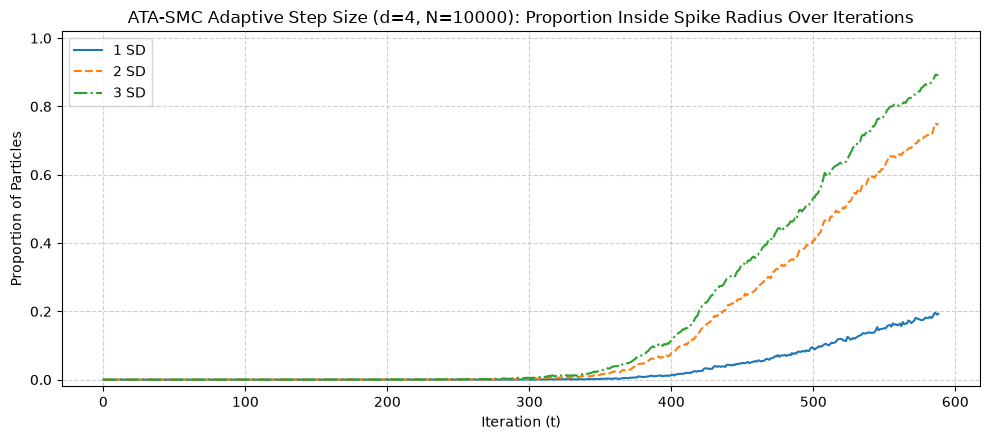

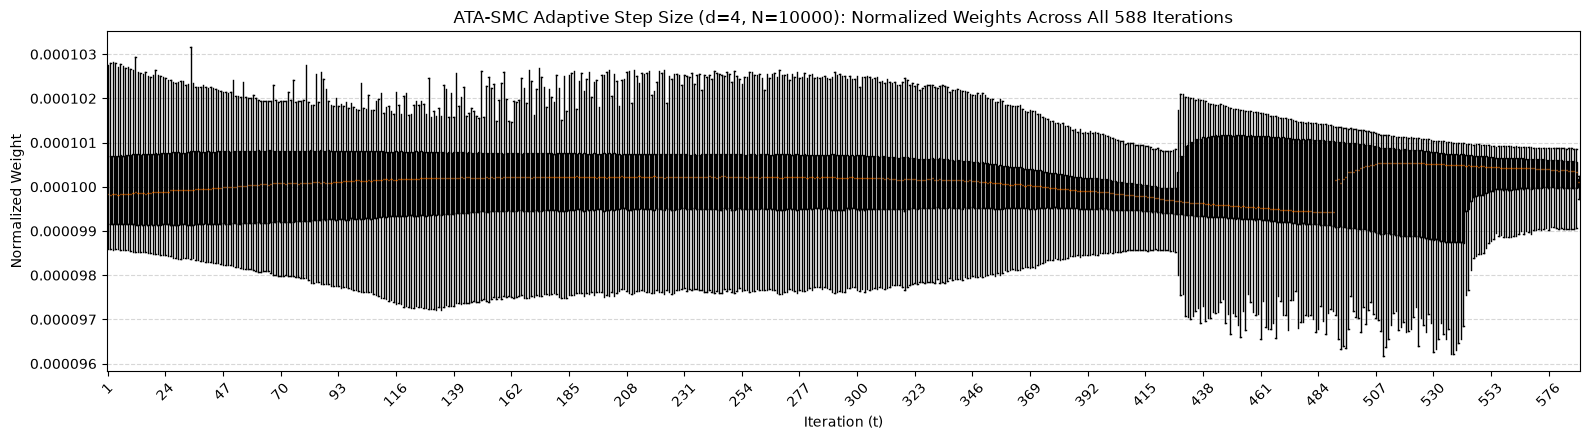

d=6


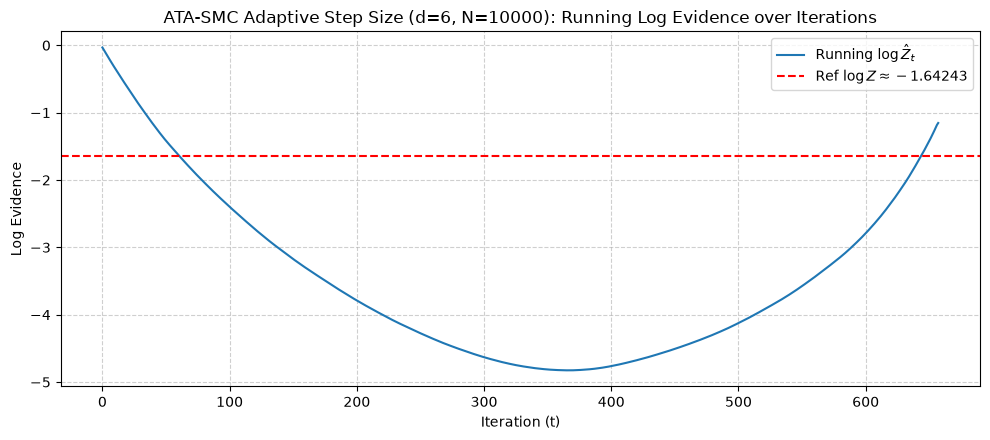

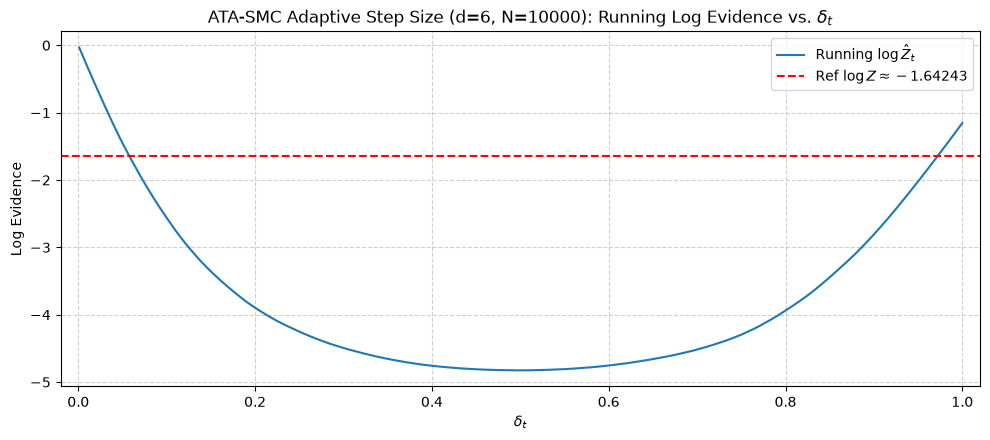

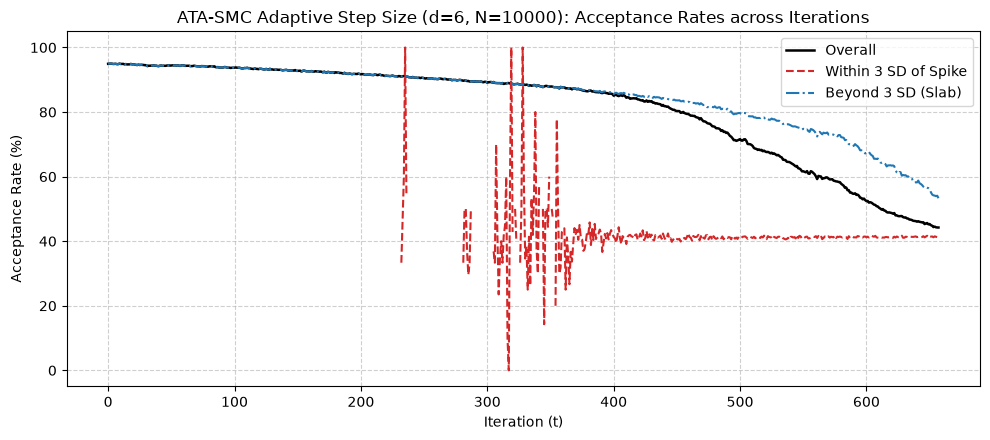

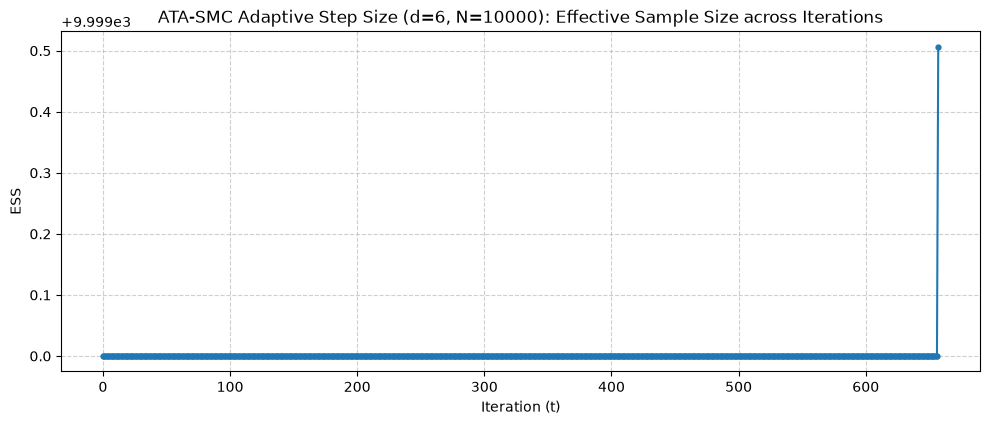

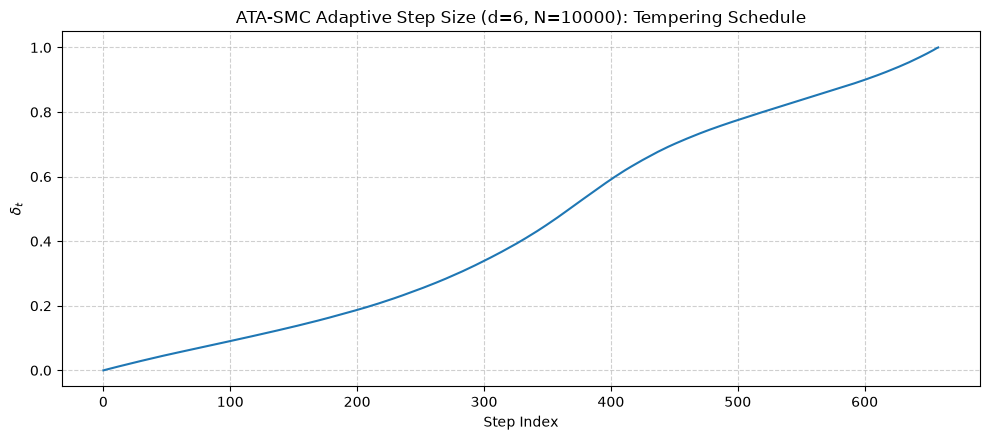

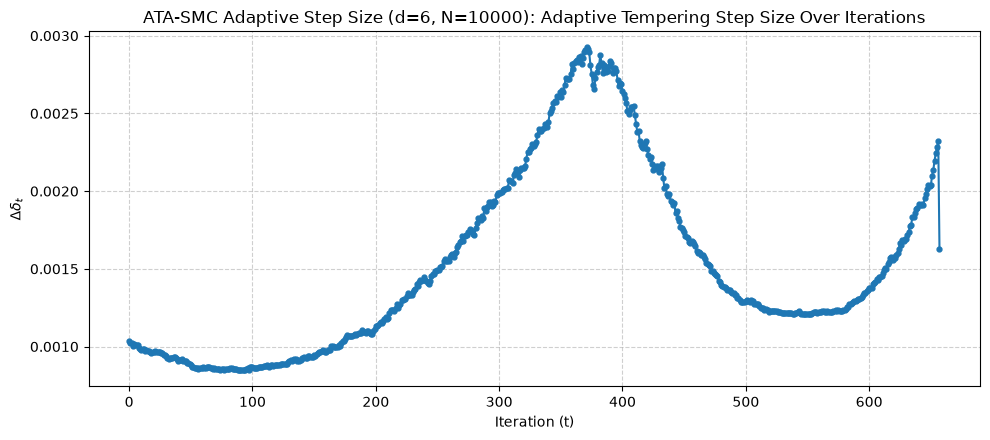

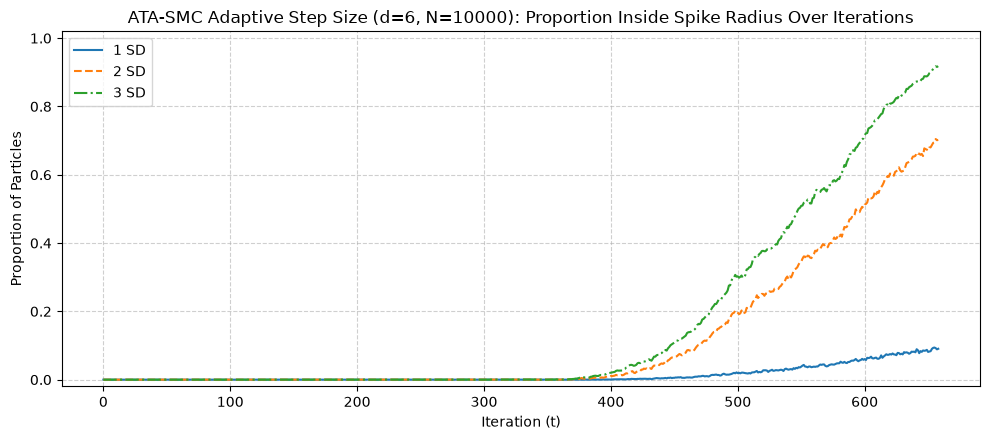

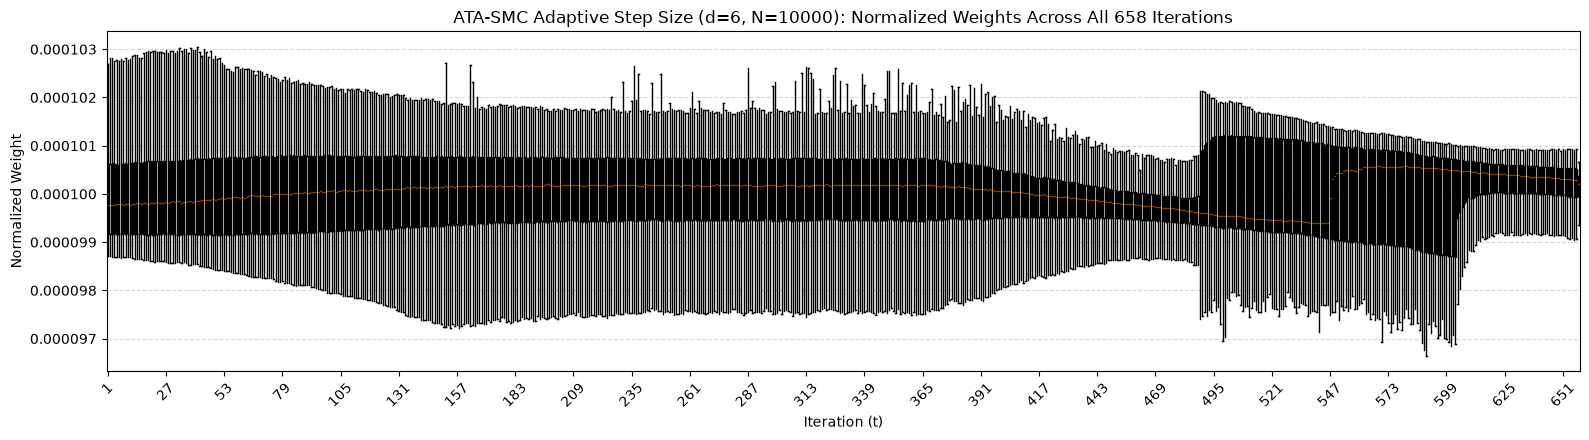

d=8


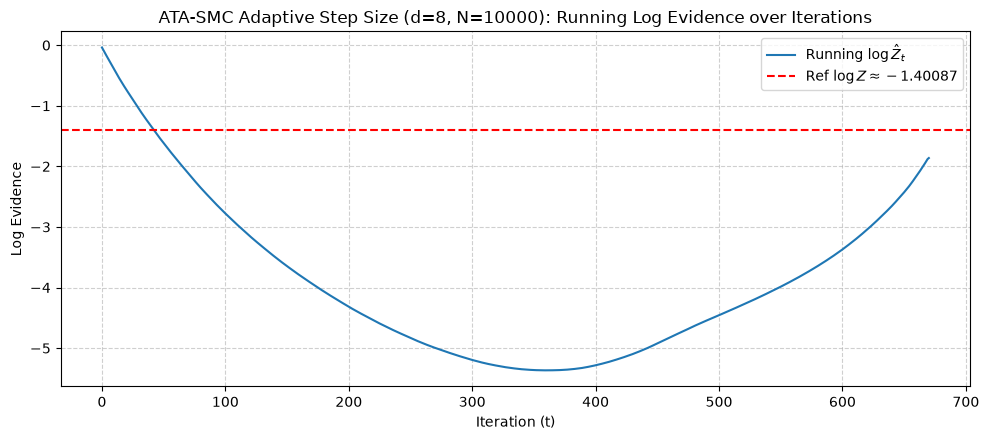

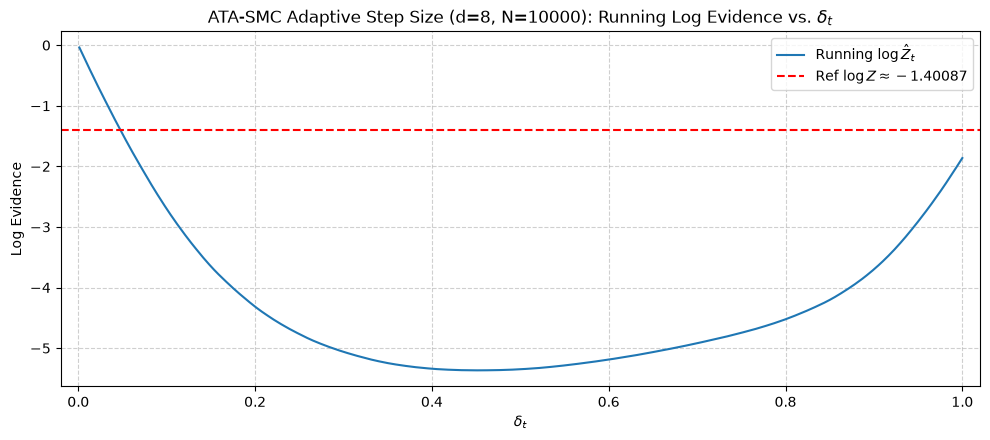

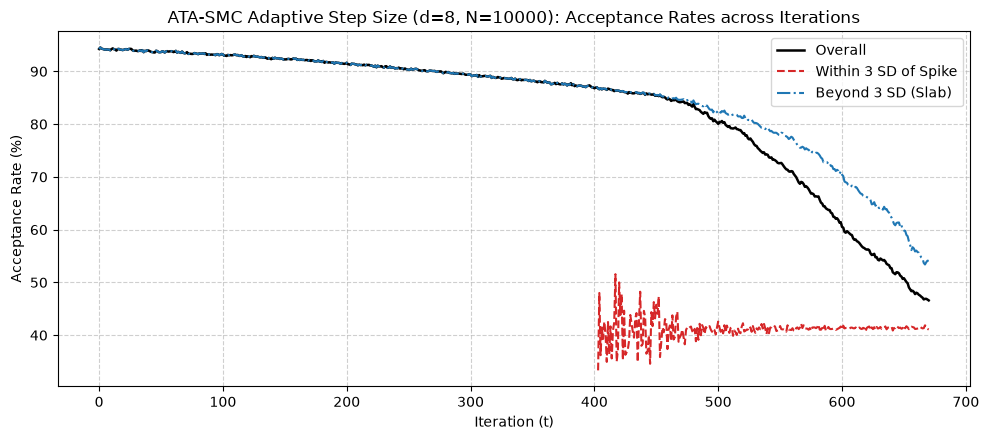

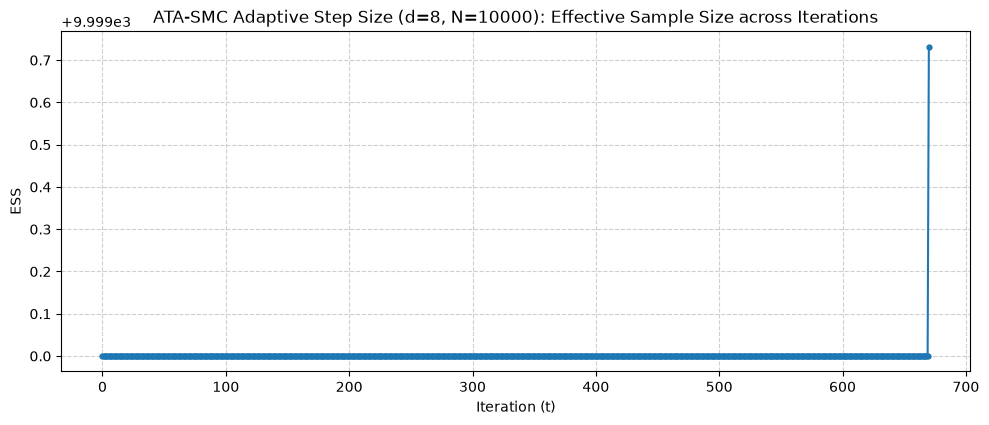

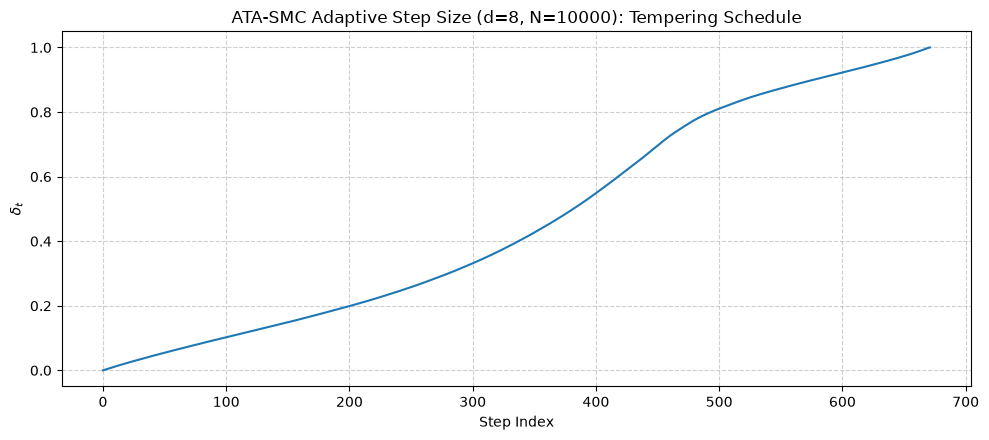

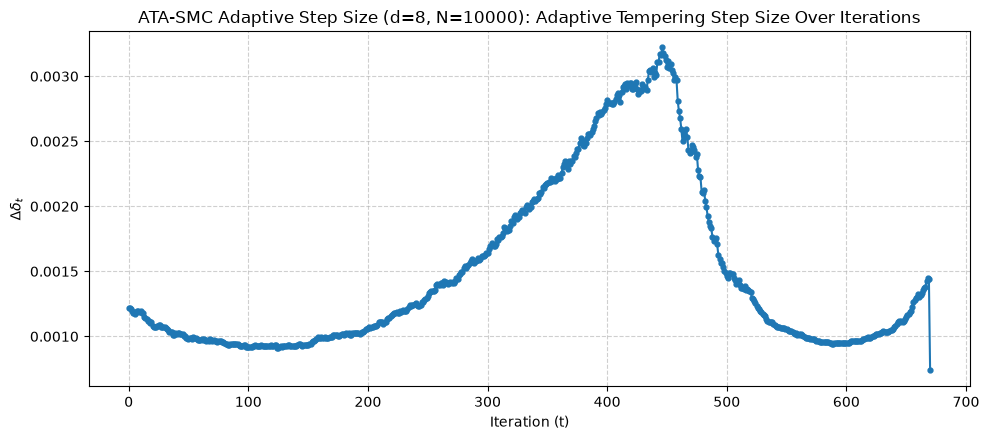

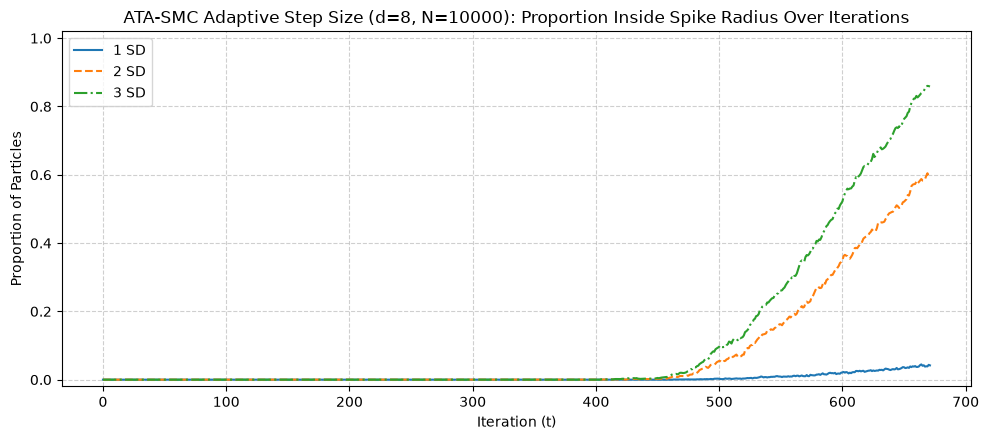

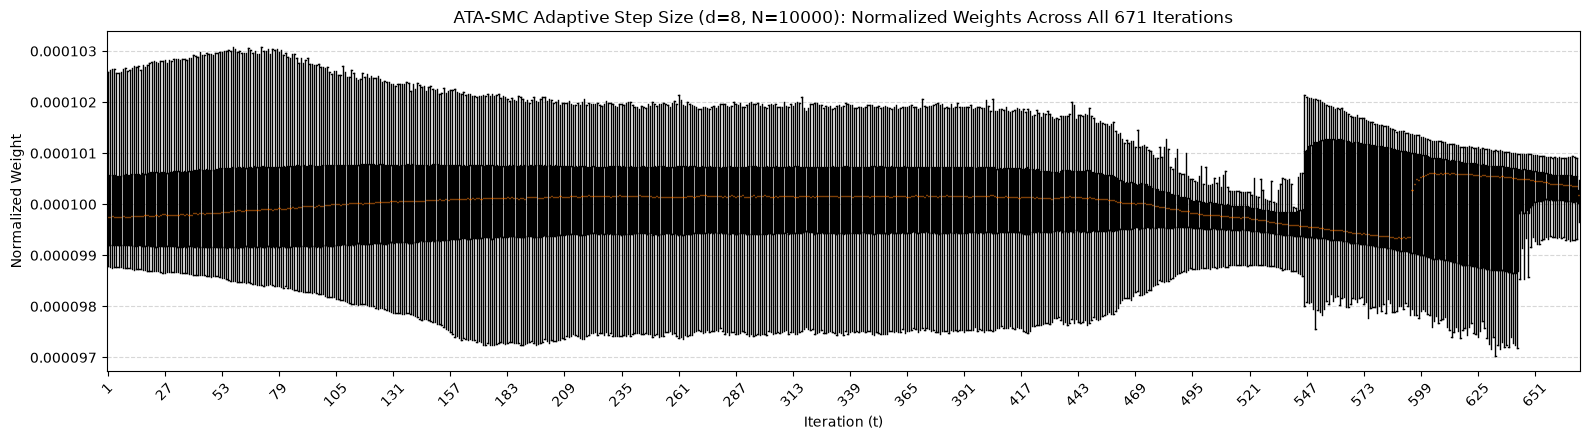

d=10


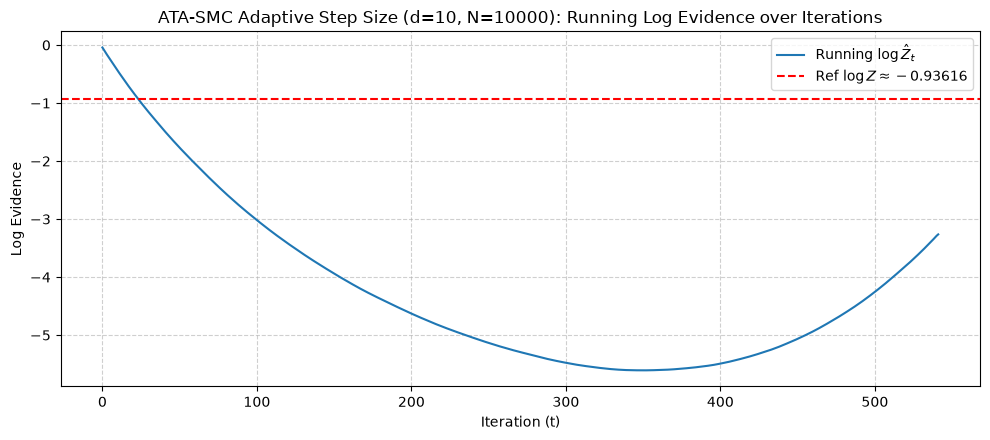

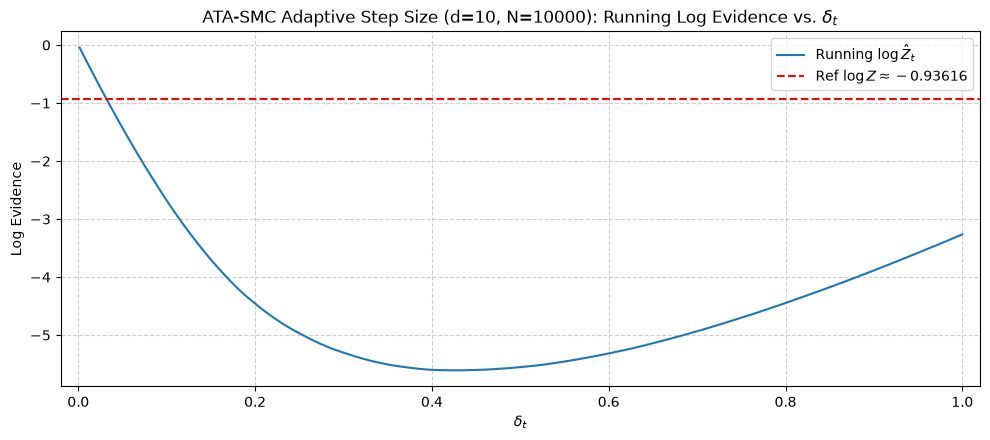

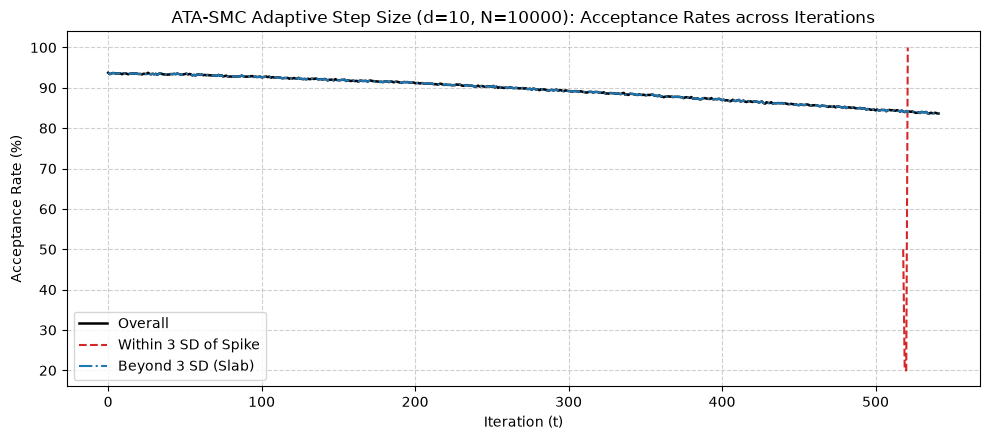

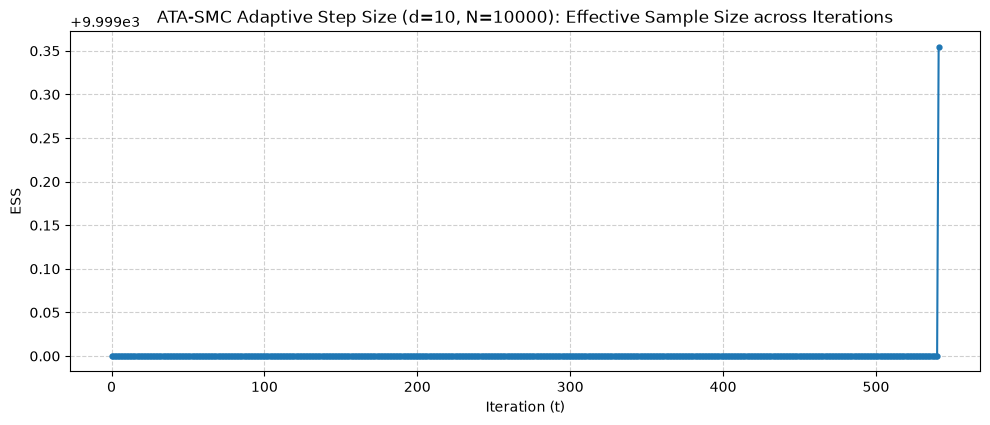

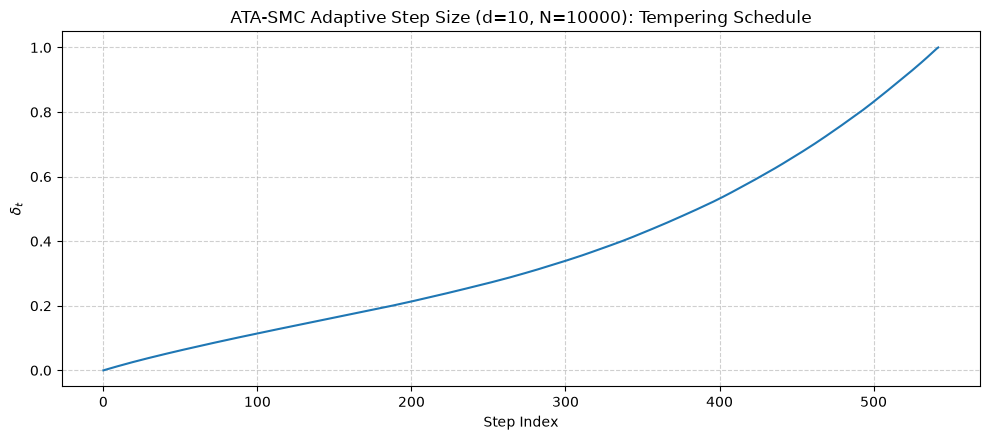

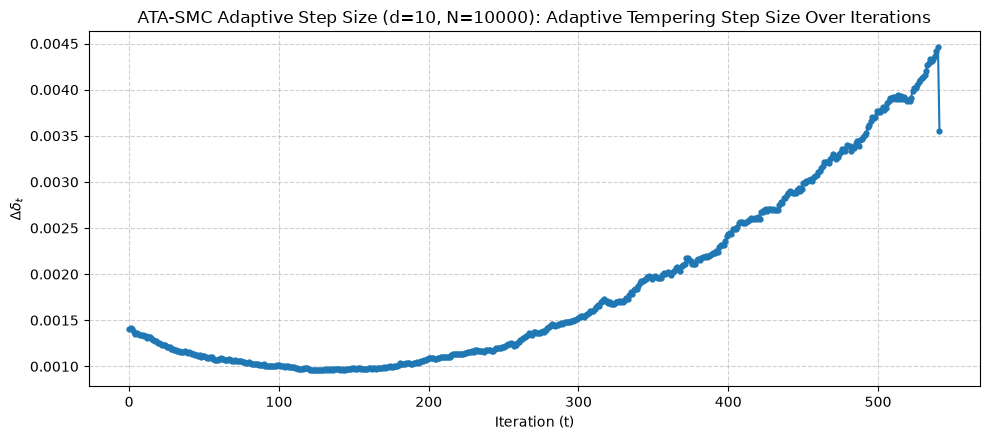

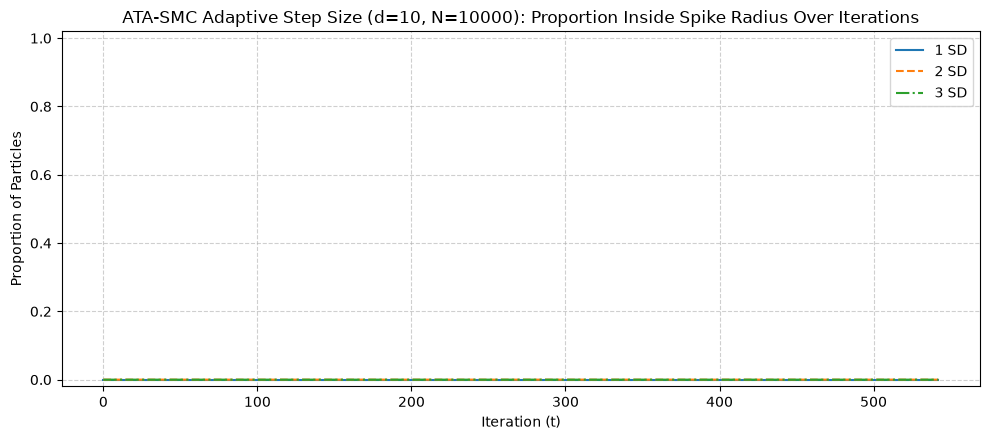

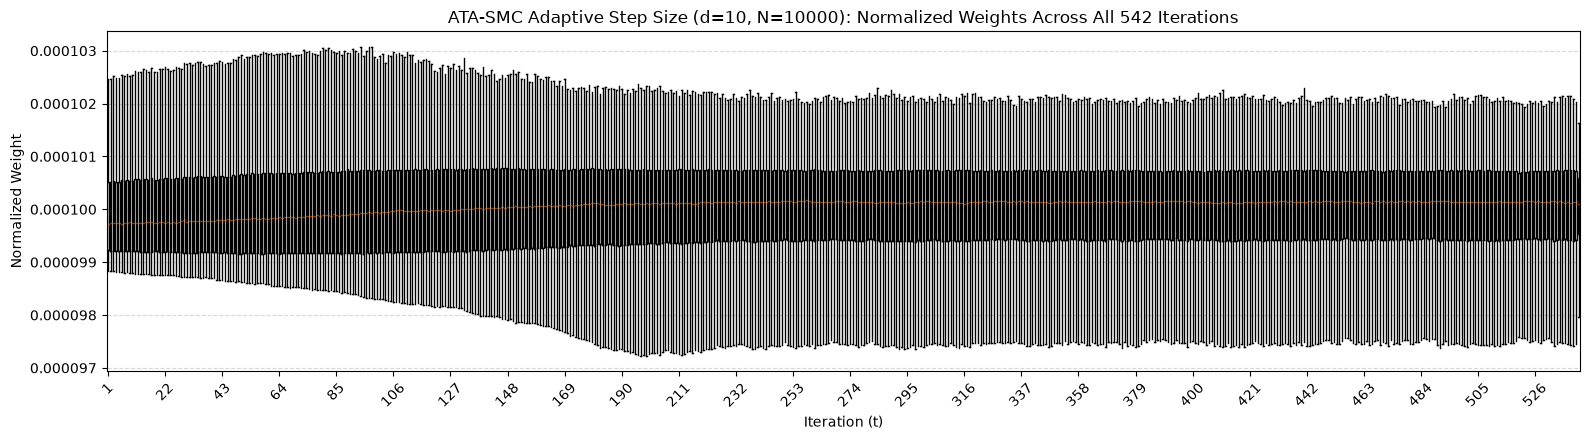

In [22]:
class Options:
    pass


dims = [2, 4, 6, 8, 10]
N = 10000
repeats = 10
num_repeats = 1


def run_ata_smc_for_d(d_val, num_repeats=1, plot_diagnostics=True):
    d_int = int(d_val)
    print(f"d={d_int}")
    ref_log_z = float(log_z_by_d[d_int])
    ref_z = float(z_by_d[d_int])

    rows = []
    for i in range(num_repeats):
        options = Options()
        options.N = N
        options.d = d_int
        options.alpha = 0.9999
        options.R = repeats
        options.sig = 0.1

        np.random.seed(i)
        t_start = time.time()
        (
            log_evidence,
            count_loglike,
            gammavar,
            ess,
            log_unnormalized_w,
            normalized_w,
            prop_1sd,
            prop_2sd,
            prop_3sd,
            log_evidence_t,
            accept_rate_t,
            accept_spike_t,
            accept_slab_t,
            total_prop_spike,
            total_prop_slab,
        ) = ATA_SMC_bespoke_RW_adaptive(
            loglike_fn, logprior_fn, simprior_fn, options, False
        )
        t_elapsed = time.time() - t_start

        if plot_diagnostics:
            plot_ata_smc_diagnostics(
                gammavar=gammavar,
                log_evidence_t=log_evidence_t,
                accept_rate_t=accept_rate_t,
                accept_spike_t=accept_spike_t,
                accept_slab_t=accept_slab_t,
                prop_1sd=prop_1sd,
                prop_2sd=prop_2sd,
                prop_3sd=prop_3sd,
                normalized_w=normalized_w,
                ess=ess,
                true_log_z=ref_log_z,
                label_prefix=f"ATA-SMC Adaptive Step Size (d={d_int}, N={N})",
            )

        rows.append({
            "d": d_int,
            "repeat": i,
            "log_evidence": log_evidence,
            "ref_log_z": ref_log_z,
            "log_err": log_evidence - ref_log_z,
            "Z": np.exp(log_evidence),
            "ref_Z": ref_z,
            "count_loglike": count_loglike,
            "elapsed_sec": t_elapsed,
            "prop_1sd": prop_1sd,
            "prop_2sd": prop_2sd,
            "prop_3sd": prop_3sd,
            "total_prop_spike": total_prop_spike,
            "total_prop_slab": total_prop_slab,
        })
    return pd.DataFrame(rows)


df_ata_smc_2 = pd.concat(
    [
        run_ata_smc_for_d(d_val, num_repeats=num_repeats, plot_diagnostics=True)
        for d_val in dims
    ],
    ignore_index=True,
)

In [23]:
df_ata_smc_2["ratio_spike_slab"] = df_ata_smc_2["total_prop_spike"] / df_ata_smc_2["total_prop_slab"]
df_ata_smc_2["true_Z"] = df_ata_smc_2["d"].map(z_by_d)
df_ata_smc_2["true_log_Z"] = df_ata_smc_2["d"].map(log_z_by_d)
df_ata_smc_2["abs_error"] = np.sqrt((df_ata_smc_2["Z"] - df_ata_smc_2["true_Z"]) ** 2)
df_ata_smc_2[["d", "log_evidence", "true_log_Z", "Z", "true_Z", "abs_error", "total_prop_spike", "total_prop_slab", "ratio_spike_slab"]]

,d,log_evidence,true_log_Z,Z,true_Z,abs_error,total_prop_spike,total_prop_slab,ratio_spike_slab
0,2,-1.141664,-1.144730,0.319287,0.318310,0.000977,89796,10204,8.800078
1,4,-1.558689,-1.596313,0.210412,0.202642,0.007769,85070,14930,5.697924
2,6,-1.153557,-1.642430,0.315513,0.193509,0.122003,76706,23294,3.292951
3,8,-1.862421,-1.400866,0.155296,0.246383,0.091087,57508,42492,1.353384
4,10,-3.263983,-0.936158,0.038236,0.392131,0.353896,0,100000,0.000000
